# Разведочный анализ данных о слабостях смарт-контрактов

**Фёдор Ковалев · Чекпойнт 2 · 10 ноября 2026**

Смарт-контракт — программа, которая выполняется в блокчейне. Мы изучаем набор
проверок таких программ на Solidity. Цель этого этапа — разобраться в составе,
качестве и ограничениях данных и понять, какие свойства кода связаны с отмеченными
проблемами.

Одна строка исходной таблицы описывает одну проверку. В подготовленной таблице
одна строка соответствует выделенному объявлению, а столбцы SWC — типам проверяемых
слабостей. Пустая метка означает неизвестную оценку. Данные могут содержать несколько
отмеченных слабостей у одного контракта.

## Как читать и повторить анализ

Установите зависимости из `requirements.lock.txt` в Python 3.12 и выполняйте ячейки
из папки EDA или EDA/notebooks. Подготовка исходных данных выполняется через
`python src/download_cgt.py` и `python src/audit.py`. Ниже расчёты и графики находятся
непосредственно в ячейках и используют две рабочие таблицы.

Разделы 1–3 описывают весь корпус и его разметку. В разделе 4 фиксируется разделение
на исследовательскую часть `train` и заранее отложенные `validation`/`test` для следующих
этапов проекта. Зависимости признаков и меток в разделах 5–8 изучаются на `train`.


In [73]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install scipy

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip in

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
import sys
import hashlib
import json
import io
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown
from scipy.stats import spearmanr, pointbiserialr

# Путь к модулям проекта задаётся перед их импортом.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Запустите ноутбук из папки EDA"
sys.path.insert(0, str(ROOT / "src"))

from download_cgt import download, COMMIT
from solidity_lex import lex, tokenize, declarations
from audit import SWC_NAMES, save_json


### Настройки EDA

`CORE_SWCS` задаёт восемь целевых классов, а `FEATURES` — числовые характеристики кода для анализа.

In [2]:
CORE_SWCS = [101, 104, 107, 113, 114, 115, 120, 128]
FEATURES = ["n_tokens", "n_code_lines", "n_functions", "n_modifiers", "n_loops", "n_require", "n_assert", "n_low_level_calls", "n_delegatecall", "n_send_transfer", "n_tx_origin", "n_timestamp", "n_selfdestruct", "n_assembly"]


In [3]:
%matplotlib inline
root = ROOT
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (10, 5)})


## 1. Происхождение и целостность данных
SHA-256 проверяются для каждого сохранённого исходного файла. Строка исходной таблицы — проверка свойства.

In [4]:
# При готовом снимке download проверяет SHA-256 без повторного скачивания.
snapshot_manifest = download(ROOT)
print("Зафиксированная версия CGT:", snapshot_manifest["commit"])
print("Целостность сохранённых файлов проверена:", len(snapshot_manifest["files"]))


Зафиксированная версия CGT: f8cd72cf7fbbfebc809c454667eee271706a4b2b
Целостность сохранённых файлов проверена: 3113


In [5]:
assessments = pd.read_csv(ROOT / "data/raw/cgt/consolidated.csv", sep=";", dtype=str, keep_default_na=False)
raw = assessments
contracts = pd.read_csv(ROOT / "data/processed/contracts.csv", keep_default_na=False)
label_columns = contracts.filter(regex=r"^swc_\d+$").columns.tolist()
contracts[label_columns] = contracts[label_columns].replace("", np.nan).astype(float)
targets = contracts.set_index("entity_id")[label_columns]
# Список исходников получаем из папки с кодом, без отдельного CSV.
sources = pd.DataFrame({"fp_sol": [p.stem for p in sorted((ROOT / "data/raw/cgt/source").glob("*.sol"))]})


In [6]:
overview = pd.Series({
    "assessments": len(assessments),
    "dataset_entries": len(assessments[["dataset", "id"]].drop_duplicates()),
    "source_files_on_disk": len(sources),
    "contracts_with_unambiguous_binding": len(contracts),
    "preliminary_eligible_contracts": int(contracts.model_eligible_preliminary.sum()),
}, name="Количество")

print('Обзор загруженных данных:')
print(overview.to_frame())
print('\n')
print('Пример загруженных оценок:')
print(assessments.head())


Обзор загруженных данных:
                                    Количество
assessments                              20455
dataset_entries                           4190
source_files_on_disk                      3103
contracts_with_unambiguous_binding        3088
preliminary_eligible_contracts            2735


Пример загруженных оценок:
      dataset                                          id  \
0  CodeSmells  0x00430f32b8e77a456d0ab7e6f1dc1b84f4ae62e0   
1  CodeSmells  0x00430f32b8e77a456d0ab7e6f1dc1b84f4ae62e0   
2  CodeSmells  0x00430f32b8e77a456d0ab7e6f1dc1b84f4ae62e0   
3  CodeSmells  0x00430f32b8e77a456d0ab7e6f1dc1b84f4ae62e0   
4  CodeSmells  0x00430f32b8e77a456d0ab7e6f1dc1b84f4ae62e0   

                       property property_holds chain  \
0       Unchecked External Call              f  main   
1  Dos Under external influence              f  main   
2       strict balance equality              f  main   
3     Unmatched type assignment              f  main   
4  Transaction s

### Характеристики Solidity-кода

Сначала рассчитываем счётчики для каждого объекта. Функция ниже показывает правила
подсчёта токенов, функций и операций. Затем `describe()` и графики описывают распределения
этих величин. Проверки меток и выделение контрактов выполнены в `src/audit.py`.


In [7]:
def code_features(code: str) -> dict:
    document = lex(code)
    tokens = tokenize(document.clean)
    identifiers = re.findall(r"\b[A-Za-z_$][\w$]*\b", document.mask)
    words = pd.Series(identifiers).value_counts().to_dict() if identifiers else {}
    fields = {
        "n_chars": len(code), "n_lines": len(code.splitlines()),
        "n_code_lines": sum(bool(x.strip()) for x in document.clean.splitlines()),
        "n_tokens": len(tokens), "n_unique_tokens": len(set(tokens)),
        "n_contracts": len(declarations(code, document)),
        "n_functions": int(words.get("function", 0)),
        "n_modifiers": int(words.get("modifier", 0)),
        "n_loops": int(sum(words.get(x, 0) for x in ("for", "while"))),
        "n_require": int(words.get("require", 0)), "n_assert": int(words.get("assert", 0)),
        "n_events": int(words.get("event", 0)),
        "n_low_level_calls": len(re.findall(r"\.\s*(?:call|callcode|delegatecall|staticcall)\b", document.mask)),
        "n_delegatecall": len(re.findall(r"\.\s*delegatecall\b", document.mask)),
        "n_send_transfer": len(re.findall(r"\.\s*(?:send|transfer)\b", document.mask)),
        "n_tx_origin": len(re.findall(r"\btx\s*\.\s*origin\b", document.mask)),
        "n_timestamp": len(re.findall(r"\bblock\s*\.\s*timestamp\b|\bnow\b", document.mask)),
        "n_selfdestruct": int(words.get("selfdestruct", 0) + words.get("suicide", 0)),
        "n_assembly": int(words.get("assembly", 0)),
        "comment_char_fraction": sum(len(x) for x in document.comments) / max(len(code), 1),
        "has_annotation_comments": bool(re.search(r"@vulnerable|<yes>|<report>|\bSWC-\d+\b|\bbuggy\b", "\n".join(document.comments), re.I)),
        "has_synthetic_identifiers": bool(re.search(r"\b\w*(?:_re_ent|_txorigin|_overflow|_timestamp|_tod|_unchk|bug\d|bug_)[\w]*\b", document.mask, re.I)),
        "lex_errors": "|".join(document.errors),
        "pragma": "|".join(re.findall(r"\bpragma\s+solidity\s+([^;]+);", document.mask)),
    }
    fields["is_empty"] = not document.clean.strip()
    return fields


In [8]:
source_features = pd.DataFrame([
    code_features((ROOT / f"data/raw/cgt/source/{fp}.sol").read_text())
    for fp in sources.fp_sol
], index=sources.index)
sources = sources.drop(columns=source_features.columns, errors="ignore").join(source_features)

contract_features = pd.DataFrame([
    code_features((ROOT / path).read_text()) for path in contracts.model_input
], index=contracts.index).drop(columns="pragma")
# pragma относится к исходному файлу, из которого выделен контракт.
contracts = contracts.drop(columns=contract_features.columns, errors="ignore").join(contract_features)
contracts.to_csv(ROOT / "data/processed/contracts.csv", index=False)
display(contracts[["contract_name", "n_tokens", "n_functions", "n_loops"]].head())


,contract_name,n_tokens,n_functions,n_loops
0,demo,90,1,1
1,TestBotAttack,454,7,6
2,proxy,289,2,0
3,WalletProxy,185,2,0
4,DerivedA,81,3,0


## 2. Основные статистики и пропуски
Пустые строки метаданных переводятся в NA только для описания. Исходная таблица сохраняется неизменённой. Статистики рассчитываются и отображаются в ячейках.

In [9]:
assessment_description = assessments.replace("", pd.NA).describe(include="all")
contract_description = contracts.replace("", pd.NA).describe(include="all")
print('Описание оценок:')
print(assessment_description)
print('\n')
print('Описание контрактов:')
print(contract_description)

Описание оценок:
           dataset                                          id    property  \
count        20455                                       20455       20455   
unique          13                                        4106         160   
top     CodeSmells  0x6a92b2804eaef97f222d003c94f683333e330693  Reentrancy   
freq         10395                                          24        1531   

       property_holds  chain                                        addr  \
count           20455  19626                                       19626   
unique              2      4                                        2559   
top                 f   main  0x6a92b2804eaef97f222d003c94f683333e330693   
freq            14836  18032                                          31   

          contractname                            fp_sol  \
count            19400                             19456   
unique            1963                              3103   
top     MultiSigWallet  c319c9d

In [10]:
missing = pd.DataFrame({
    "feature": assessments.columns,
    "missing_n": assessments.eq("").sum().to_numpy(),
    "missing_pct": assessments.eq("").mean().to_numpy() * 100,
})
display(missing)
print("Доля пустых исходных ячеек:", f"{assessments.eq('').to_numpy().mean():.2%}")
print("Доля неизвестных таргетов:", f"{targets.isna().to_numpy().mean():.2%}")


,feature,missing_n,missing_pct
0,dataset,0,0.000000
1,id,0,0.000000
2,property,0,0.000000
3,property_holds,0,0.000000
4,chain,829,4.052799
5,addr,829,4.052799
6,contractname,1055,5.157663
7,fp_sol,999,4.883891
8,fp_sol2,999,4.883891
9,fp_bytecode,2145,10.486434


Доля пустых исходных ячеек: 8.31%
Доля неизвестных таргетов: 88.65%


### Почему пропуски нельзя заполнить одним правилом
Отсутствие адреса, исходника и оценки свойства имеет разный смысл. Профили пропусков по источникам подтверждают структурную неполноту. Неизвестные и конфликтующие SWC-метки остаются неизвестными.

In [11]:
source_missing = assessments.replace("", pd.NA).groupby("dataset").apply(
    lambda part: part.isna().mean(), include_groups=False
)
print('Доля пустых исходных ячеек по датасетам:')
print(source_missing)
print('\n')
print('Пример контрактов с конфликтующими SWC:')
print(contracts.loc[contracts.conflicting_swcs.ne(""), ["contract_name", "conflicting_swcs"]].head(10))

Доля пустых исходных ячеек по датасетам:
                 id  property  property_holds     chain      addr  \
dataset                                                             
CodeSmells      0.0       0.0             0.0  0.000000  0.000000   
ContractFuzzer  0.0       0.0             0.0  0.117166  0.117166   
Doublade        0.0       0.0             0.0  0.300725  0.300725   
EthRacer        0.0       0.0             0.0  0.000000  0.000000   
EverEvolvingG   0.0       0.0             0.0  0.000000  0.000000   
JiuZhou         0.0       0.0             0.0  1.000000  1.000000   
NPChecker       0.0       0.0             0.0  0.000000  0.000000   
NotSoSmartC     0.0       0.0             0.0  0.705882  0.705882   
SBcurated       0.0       0.0             0.0  0.503876  0.503876   
SWCregistry     0.0       0.0             0.0  0.913793  0.913793   
SolidiFI        0.0       0.0             0.0  1.000000  1.000000   
Zeus            0.0       0.0             0.0  0.000000  0.000

Конфликтующих пар контракт—SWC: 180
Покрытие разметкой: все 37 категорий
    contracts
0         231
1        1370
2          27
3           2
4           4
5          30
6         209
7         676
8           6
9          46
10        449
11         22
12         16


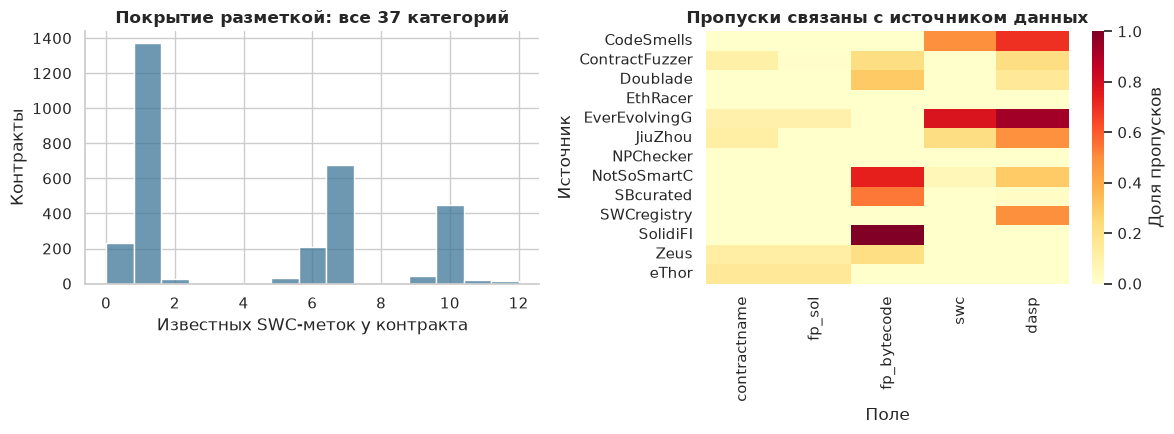

In [12]:
conflict_sets = contracts.conflicting_swcs.map(lambda value: set(value.split("|")) if value else set())
print("Конфликтующих пар контракт—SWC:", int(conflict_sets.map(len).sum()))
label_coverage = targets.notna().sum(axis=1)
print("Покрытие разметкой: все 37 категорий")
print(label_coverage.value_counts().sort_index().to_frame("contracts"))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(label_coverage, ax=axes[0], color="#3d7598")
axes[0].set(title="Покрытие разметкой: все 37 категорий", xlabel="Известных SWC-меток у контракта", ylabel="Контракты")
sns.heatmap(source_missing[["contractname", "fp_sol", "fp_bytecode", "swc", "dasp"]], ax=axes[1], vmin=0, vmax=1, cmap="YlOrRd", cbar_kws={"label": "Доля пропусков"})
axes[1].set(title="Пропуски связаны с источником данных", xlabel="Поле", ylabel="Источник")

fig.tight_layout()
plt.show()

### Проверка качества данных

Проверяем допустимость значений, уникальность объектов и доступность кода. Сводка
показывает технические ошибки отдельно от отсутствия данных и спорных оценок.
Записи без доступного исходника и с неоднозначной привязкой остаются в исходной
таблице. Конфликтующие SWC-оценки сохраняются как неизвестные.

Проверки текста и скобок ограничены лексическим разбором. Компиляция с историческими
версиями языка и подтверждение возможности эксплуатации относятся к дальнейшей работе.


In [13]:
raw_required = ["dataset", "id", "property", "property_holds"]
source_ids = set(sources.fp_sol)
source_metadata = contracts.drop_duplicates("fp_sol")
code_paths = contracts.model_input.map(lambda value: ROOT / value)
invalid_raw_labels = int((~assessments.property_holds.isin(["t", "f"])).sum())
invalid_target_cells = int((targets.notna() & ~targets.isin([0, 1])).to_numpy().sum())
empty_code = int(sum(not lex(path.read_text()).clean.strip() for path in code_paths if path.is_file()))
raw_has_source = assessments.fp_sol.ne("")
bound_checks = int(contracts.assessment_rows.map(lambda value: len(value.split("|"))).sum())
unbound_with_source = int(raw_has_source.sum()) - bound_checks
quality_checks = pd.DataFrame([
    ["Пропуски обязательных полей исходной таблицы", int(assessments[raw_required].eq("").to_numpy().sum()), "ошибка"],
    ["Недопустимые исходные оценки t/f", invalid_raw_labels, "ошибка"],
    ["Повторяющиеся ключи исходных проверок", int(assessments.duplicated(["dataset", "id", "property"]).sum()), "ошибка"],
    ["Повторяющиеся entity_id", int(contracts.entity_id.duplicated().sum()), "ошибка"],
    ["Недопустимые итоговые оценки", invalid_target_cells, "ошибка"],
    ["Непустые ссылки на отсутствующий исходник", int((raw_has_source & ~assessments.fp_sol.isin(source_ids)).sum()), "ошибка"],
    ["Отсутствующие файлы выделенного кода", int(sum(not path.is_file() for path in code_paths)), "ошибка"],
    ["Пустые фрагменты кода", empty_code, "ошибка"],
    ["Исходники с ошибками UTF-8 среди привязанных", int(source_metadata.source_decoding.ne("utf-8").sum()), "ошибка"],
    ["Исходники с лексическими замечаниями среди привязанных", int(source_metadata.source_lex_errors.ne("").sum()), "ошибка"],
    ["Выделенные фрагменты с лексическими замечаниями", int(contracts.lex_errors.ne("").sum()), "ошибка"],
    ["Проверки без ссылки на Solidity", int((~raw_has_source).sum()), "неполнота"],
    ["Проверки с исходником без однозначной привязки", unbound_with_source, "неоднозначность"],
    ["Конфликтующие пары контракт–SWC", int(contracts.conflicting_swcs.map(lambda x: len(x.split("|")) if x else 0).sum()), "спорная оценка"],
], columns=["Проверка", "Количество", "Смысл"])
display(quality_checks)


,Проверка,Количество,Смысл
0,Пропуски обязательных полей исходной таблицы,0,ошибка
1,Недопустимые исходные оценки t/f,0,ошибка
2,Повторяющиеся ключи исходных проверок,0,ошибка
3,Повторяющиеся entity_id,0,ошибка
4,Недопустимые итоговые оценки,0,ошибка
5,Непустые ссылки на отсутствующий исходник,0,ошибка
6,Отсутствующие файлы выделенного кода,0,ошибка
7,Пустые фрагменты кода,0,ошибка
8,Исходники с ошибками UTF-8 среди привязанных,0,ошибка
9,Исходники с лексическими замечаниями среди при...,0,ошибка


## 3. Баланс классов и дубликаты

Весь подготовленный корпус используется для аудита 37 наблюдаемых категорий.
Для подробного сравнения выбраны восемь типов слабостей с достаточным числом
положительных и отрицательных групп. Синтетические контракты SolidiFI сохраняются
в общем аудите. Основной состав для сопоставимого анализа включает 2 735 контрактов
без SolidiFI и библиотек. Это выбранный протокол, пользу которого можно проверять
отдельным сравнением на последующих этапах.


In [14]:
entities = contracts
eligible = contracts.loc[contracts.model_eligible_preliminary].set_index("entity_id")
eligible

,fp_sol,contract_name,kind,group_id,model_input,same_file_bases_n,external_bases,source_lex_errors,source_decoding,pragma,...,n_send_transfer,n_tx_origin,n_timestamp,n_selfdestruct,n_assembly,comment_char_fraction,has_annotation_comments,has_synthetic_identifiers,lex_errors,is_empty
entity_id,,,,,,,,,,,,,,,,,,,,,
0020e4950bda6fa15d9c75ad,fac43d3a00a372149391742bf3542bf3,demo,contract,g_ec52fe5519874858981ccf66390fa1f8,data/processed/model_inputs/0020e4950bda6fa15d...,0,,,utf-8,^0.4.0,...,0,0,0,0,0,0.0,False,False,,False
0021522ab986ec6d23e8c97a,d12d66ed92232a208810e54ff3df16fb,TestBotAttack,contract,g_d12d66ed92232a208810e54ff3df16fb,data/processed/model_inputs/0021522ab986ec6d23...,0,,,utf-8,^0.4.6,...,0,0,0,0,0,0.0,False,False,,False
00259b039172dadbcac9ff3d,91ccd3e999b8b46d20346233a4bf94ee,proxy,contract,g_91ccd3e999b8b46d20346233a4bf94ee,data/processed/model_inputs/00259b039172dadbca...,0,,,utf-8,0.6.2,...,0,0,0,0,0,0.0,False,False,,False
0047e588b7ed0b1bcd72b6b1,e08b284943b3305327c42034ec614c36,WalletProxy,contract,g_e08b284943b3305327c42034ec614c36,data/processed/model_inputs/0047e588b7ed0b1bcd...,2,,,utf-8,,...,0,0,0,0,1,0.0,False,False,,False
00516ae62751bf410a3d9020,c737b2fa419ab726965c63d4b2176a61,DerivedA,contract,g_c737b2fa419ab726965c63d4b2176a61,data/processed/model_inputs/00516ae62751bf410a...,0,Base,,utf-8,>=0.5.0,...,0,0,0,0,0,0.0,False,False,,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ff71833641bee68a1b1e0375,a8a9e95eeead48768fdc2cfd8f7a57ad,HP,contract,g_12f435b9c05e4a750edac10375d7128a,data/processed/model_inputs/ff71833641bee68a1b...,2,,,utf-8,^0.4.18,...,2,0,0,0,0,0.0,False,False,,False
ff7b297178910317707d0c42,07e178810f331d9443ca152241111e46,OraclesPresale,contract,g_07e178810f331d9443ca152241111e46,data/processed/model_inputs/ff7b29717891031770...,0,,,utf-8,^0.4.18,...,2,0,0,0,0,0.0,False,False,,False
ff94f5a696be4755c901c205,6c035f1bd86541a724d4acd4e4ae3b51,EX,contract,g_12f435b9c05e4a750edac10375d7128a,data/processed/model_inputs/ff94f5a696be4755c9...,2,,,utf-8,^0.4.18,...,2,0,0,0,0,0.0,False,False,,False


In [15]:
class_rows = []

for column in label_columns:
    swc = int(column.removeprefix("swc_"))
    y = contracts[column]
    known_eligible = eligible[column]
    pos_groups = eligible.loc[known_eligible == 1, "group_id"].nunique()
    neg_groups = eligible.loc[known_eligible == 0, "group_id"].nunique()
    class_rows.append({
        "swc": swc, "name": SWC_NAMES.get(swc, "SWC"),
        "positive": int(y.eq(1).sum()), "negative": int(y.eq(0).sum()),
        "conflicting": int(conflict_sets.map(lambda values: str(swc) in values).sum()),
        "unknown": int(y.isna().sum()),
        "eligible_positive": int(known_eligible.eq(1).sum()),
        "eligible_negative": int(known_eligible.eq(0).sum()),
        "eligible_positive_groups": pos_groups, "eligible_negative_groups": neg_groups,
        "focus_class": swc in CORE_SWCS,
    })
class_summary = pd.DataFrame(class_rows)
print('Обзор SWC-классов:')
print(class_summary)
dataset_summary = assessments.groupby("dataset").agg(
    assessments=("id", "size"), entries=("id", "nunique"),
    source_refs=("fp_sol", lambda values: values[values.ne("")].nunique()),
).sort_values("assessments", ascending=False)
print('Обзор датасетов:')
print(dataset_summary)

Обзор SWC-классов:
    swc                                   name  positive  negative  \
0   100            Function Default Visibility         1         1   
1   101           Integer Overflow / Underflow       712       284   
2   102              Outdated Compiler Version         1         0   
3   103                        Floating Pragma       513        46   
4   104            Unchecked Call Return Value       341      1263   
5   105           Unprotected Ether Withdrawal        58         4   
6   106               Unprotected SELFDESTRUCT         6         3   
7   107                             Reentrancy       153      1269   
8   108      State Variable Default Visibility         3         1   
9   109          Uninitialized Storage Pointer         5         3   
10  110                       Assert Violation        15         8   
11  111            Use of Deprecated Functions         2         2   
12  112       Delegatecall to Untrusted Callee        24         6   
1

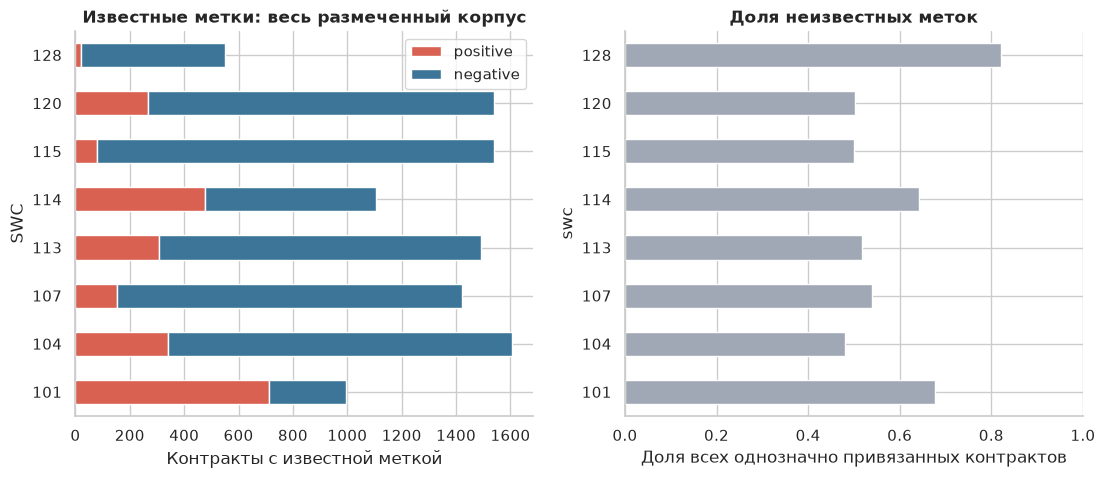

In [16]:
support = class_summary
core_support = support[support.swc.isin(CORE_SWCS)].set_index("swc")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
core_support[["positive", "negative"]].plot.barh(ax=axes[0], color=["#d86152", "#3d7598"], stacked=True)
axes[0].set_title("Известные метки: весь размеченный корпус")
axes[0].set_xlabel("Контракты с известной меткой")
axes[0].set_ylabel("SWC")
(core_support.unknown / len(entities)).plot.barh(ax=axes[1], color="#a1a8b5")
axes[1].set_title("Доля неизвестных меток")
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Доля всех однозначно привязанных контрактов")
plt.show()

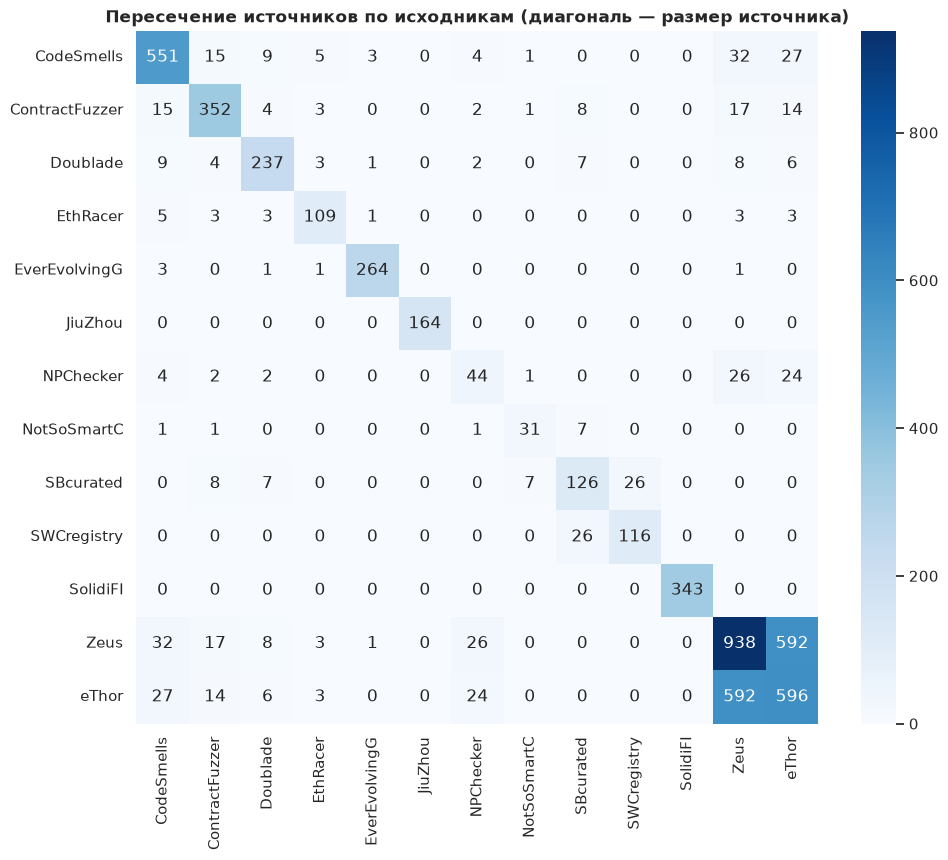

In [17]:
# Source overlap before deduplication, based on the same exact source file.
mapping = raw[raw.fp_sol.ne("")].groupby("dataset").fp_sol.apply(set).to_dict()
names = sorted(mapping)
overlaps = pd.DataFrame([[len(mapping[a] & mapping[b]) for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(overlaps, cmap="Blues", annot=True, fmt="d", ax=ax)
ax.set_title("Пересечение источников по исходникам (диагональ — размер источника)")
plt.show()

## 4. Разбиение и границы EDA

Группы похожего кода целиком удерживаются в одной части данных. Разбиение выбрано
по размерам и известным меткам с seed=42. `train` из 1 926 контрактов здесь служит
исследовательской частью. `validation` и `test` заранее отложены для следующих этапов.
Так выводы EDA можно использовать при разработке подхода, сохраняя отдельные данные
для его дальнейшей проверки. В этом чекпойнте оцениваем состав этих частей.


In [18]:
def grouped_split(entities: pd.DataFrame, targets: pd.DataFrame, root=ROOT):
    """Используем готовую колонку partition или создаём разбиение по группам.

    Новый вариант выбирается по размерам и балансу меток с seed=42.
    Связанные объекты удерживаются вместе. Результат сохраняется в contracts.csv.
    """

    eligible = entities[entities.model_eligible_preliminary].copy()
    if "partition" in eligible and eligible.partition.ne("").any():
        assert eligible.partition.isin(["train", "validation", "test"]).all(), "Разбиение заполнено не полностью"
        split = eligible[["entity_id", "group_id", "partition"]].sort_values("entity_id").reset_index(drop=True)
        assert eligible.groupby("group_id").partition.nunique().max() == 1, "Группа попала в разные выборки"
        return split

    eligible = eligible.sort_values("entity_id").set_index("entity_id")
    y = targets.reindex(eligible.index)
    indicator = pd.DataFrame(index=eligible.index)

    for swc in CORE_SWCS:
        for value in (0, 1):
            indicator[f"swc_{swc}_{value}"] = y[f"swc_{swc}"].eq(value).astype(int)

    indicator["entities"] = 1
    indicator["group_id"] = eligible.group_id
    grouped = indicator.groupby("group_id").sum().sort_index()
    values = grouped.to_numpy()
    total = values.sum(axis=0)
    ratios = np.array([0.70, 0.15, 0.15])
    rng = np.random.default_rng(42)
    n = len(grouped)
    cuts = [round(0.70 * n), round(0.85 * n)]
    best = None

    for _ in range(2000):
        order = rng.permutation(n)
        parts = np.split(order, cuts)
        counts = np.stack([values[p].sum(axis=0) for p in parts])
        if (counts[:, :-1] < 3).any():
            continue
        discrepancy = counts / np.maximum(total, 1) - ratios[:, None]
        loss = float(np.mean(discrepancy[:, :-1] ** 2) + np.mean(discrepancy[:, -1] ** 2))
        if best is None or loss < best[0]:
            best = loss, parts

    if best is None:
        raise RuntimeError("Не удалось подобрать разбиение с нужным числом примеров каждого класса")
    assignments = {}

    for name, indices in zip(("train", "validation", "test"), best[1]):
        assignments.update({grouped.index[i]: name for i in indices})
    split = eligible[["group_id"]].copy()
    split["partition"] = split.group_id.map(assignments)
    split = split.reset_index()
    assignments_by_id = split.set_index("entity_id").partition
    entities["partition"] = entities.entity_id.map(assignments_by_id).fillna("")
    entities.to_csv(root / "data/processed/contracts.csv", index=False)
    
    return split


In [19]:
decisions = json.loads((ROOT / "decisions.json").read_text())
assert decisions["stage1_approved"] and decisions["approved_swcs"] == CORE_SWCS
split = grouped_split(contracts, targets, ROOT)
assert split.groupby("group_id").partition.nunique().max() == 1
assert split.entity_id.is_unique
input_check = contracts[contracts.model_eligible_preliminary]
assert input_check.groupby("model_input_hash").partition.nunique().max() == 1
assert input_check.groupby("canonical_model_input_hash").partition.nunique().max() == 1

In [20]:
contracts["partition"] = contracts.entity_id.map(split.set_index("entity_id").partition).fillna("")
entities = contracts
train = entities[entities.partition.eq("train")].set_index("entity_id")
train_y = targets.reindex(train.index)
train_targets = train_y
print('Обзор контрактов и исследовательской части:')
print(entities.replace("", pd.NA).describe(include="all"))
print('\n')
print('Обзор исследовательской части:')
print(train.replace("", pd.NA).describe(include="all"))

Обзор контрактов и исследовательской части:
                       entity_id                            fp_sol  \
count                       3088                              3088   
unique                      3088                              3047   
top     0020e4950bda6fa15d9c75ad  cd0c01291be1ee8ae25897e1248050c2   
freq                           1                                 3   
mean                         NaN                               NaN   
std                          NaN                               NaN   
min                          NaN                               NaN   
25%                          NaN                               NaN   
50%                          NaN                               NaN   
75%                          NaN                               NaN   
max                          NaN                               NaN   

       contract_name      kind                            group_id  \
count           3088      3088               

In [21]:
counts = split.groupby("partition").agg(contracts=("entity_id", "size"), groups=("group_id", "nunique")).reindex(["train", "validation", "test"])
counts["contract_fraction"] = counts.contracts / len(split)
split_labels = []

for partition, part in split.groupby("partition"):
    ty = targets.reindex(part.entity_id)
    for swc in CORE_SWCS:
        values = ty[f"swc_{swc}"]
        split_labels.append({"partition": partition, "swc": swc,
                             "positive": int(values.eq(1).sum()), "negative": int(values.eq(0).sum()),
                             "unknown": int(values.isna().sum()),
                             "positive_rate_among_known": float(values.mean())})

split_labels = pd.DataFrame(split_labels)
for swc in CORE_SWCS:
    local = split_labels[split_labels.swc.eq(swc)]
    assert local.positive.ge(3).all() and local.negative.ge(3).all()

print('Обзор разбиения на train/validation/test:')
print(counts)
print('\n')
print('Обзор разбиения на train/validation/test по SWC-классам:')
print(split_labels)
print("Для EDA связей используется train:", len(train))


Обзор разбиения на train/validation/test:
            contracts  groups  contract_fraction
partition                                       
train            1926    1326           0.704205
validation        384     284           0.140402
test              425     284           0.155393


Обзор разбиения на train/validation/test по SWC-классам:
     partition  swc  positive  negative  unknown  positive_rate_among_known
0         test  101       105        43      277                   0.709459
1         test  104        40       191      194                   0.173160
2         test  107        16       203      206                   0.073059
3         test  113        53       168      204                   0.239819
4         test  114        76        87      262                   0.466258
5         test  115         5       225      195                   0.021739
6         test  120        52       178      195                   0.226087
7         test  128         3        77      3

## 5. Распределения каждого признака и выбросы
Счётчики конструкций не являются полноценным статическим анализатором. Редкие ненулевые значения и валидные длинные контракты сохранены; формальные IQR-флаги не использовались для автоматического удаления.

In [22]:
train[FEATURES].describe()

,n_tokens,n_code_lines,n_functions,n_modifiers,n_loops,n_require,n_assert,n_low_level_calls,n_delegatecall,n_send_transfer,n_tx_origin,n_timestamp,n_selfdestruct,n_assembly
count,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000,1926.000000
mean,903.817238,124.626168,14.012980,1.602285,1.788162,4.097612,0.411215,0.216511,0.019211,1.636552,0.092939,1.502596,0.138629,0.213915
std,1430.888403,164.915876,17.784346,2.732142,4.175723,7.775474,1.558274,0.704979,0.388329,2.014698,0.961699,3.482161,0.366086,1.060719
min,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,157.000000,29.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,497.000000,71.000000,8.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1142.750000,160.000000,18.000000,2.000000,2.000000,5.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000
max,12099.000000,1455.000000,157.000000,21.000000,35.000000,65.000000,29.000000,16.000000,16.000000,16.000000,26.000000,30.000000,2.000000,9.000000


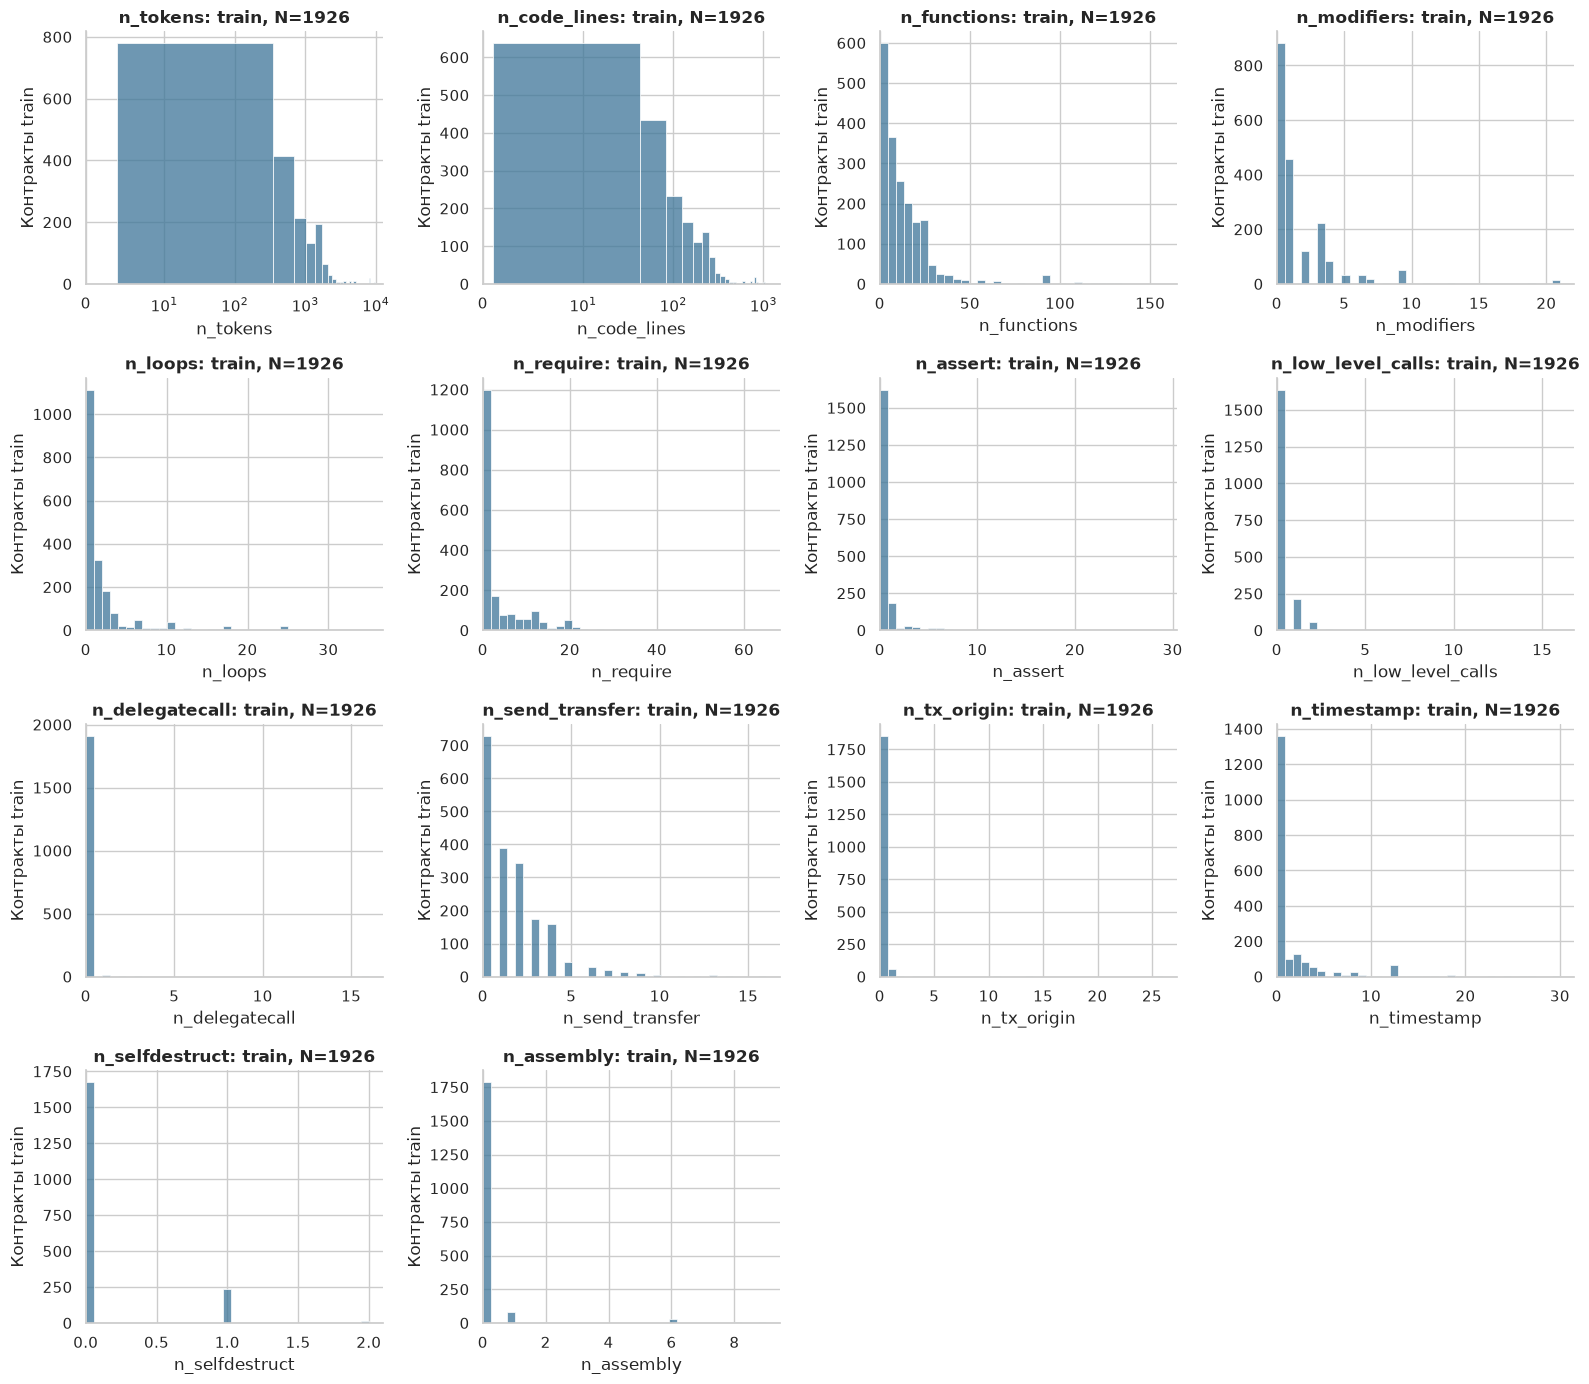

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
plot_features = FEATURES

for ax, feature in zip(axes.flat, plot_features):
    sns.histplot(train[feature], bins=35, ax=ax, color="#3d7598")
    ax.set(xlabel=feature, ylabel="Контракты train", title=f"{feature}: train, N={len(train)}")
    if feature in ("n_tokens", "n_code_lines"):
        ax.set_xscale("symlog", linthresh=10)
    ax.set_xlim(left=0)

for ax in list(axes.flat)[len(plot_features):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()


In [24]:
print(train[FEATURES].quantile([0, .01, .25, .5, .75, .95, .99, 1]))
outlier_records = []
for feature in FEATURES:
    q1, q3 = train[feature].quantile([.25, .75])
    iqr = q3 - q1
    bound = q3 + 1.5 * iqr
    above = train[feature].gt(bound)
    outlier_records.append({"feature": feature, "q1": q1, "q3": q3, "iqr": iqr,
                            "upper_fence": bound, "flagged_n": int(above.sum()),
                            "flagged_fraction": float(above.mean()), "action": "retain_valid_values"})
outliers = pd.DataFrame(outlier_records)

print('Обзор выбросов по признакам:')
print(train.nlargest(12, "n_tokens")[["fp_sol", "contract_name", "n_tokens", "n_functions", "n_code_lines", "datasets"]])
print('\n')
print('Квантили рассчитаны выше; необычные значения требуют просмотра')
print('\n')
print('Обзор выбросов:')
print(outliers)

      n_tokens  n_code_lines  n_functions  n_modifiers  n_loops  n_require  \
0.00      4.00          1.00         0.00          0.0      0.0       0.00   
0.01     19.00          5.00         1.00          0.0      0.0       0.00   
0.25    157.00         29.00         4.00          0.0      0.0       0.00   
0.50    497.00         71.00         8.00          1.0      0.0       0.00   
0.75   1142.75        160.00        18.00          2.0      2.0       5.00   
0.95   2492.50        363.25        40.00          6.0     10.0      19.00   
0.99   8523.50        874.75        99.75         12.5     24.0      37.75   
1.00  12099.00       1455.00       157.00         21.0     35.0      65.00   

      n_assert  n_low_level_calls  n_delegatecall  n_send_transfer  \
0.00       0.0                0.0             0.0              0.0   
0.01       0.0                0.0             0.0              0.0   
0.25       0.0                0.0             0.0              0.0   
0.50       0.0   

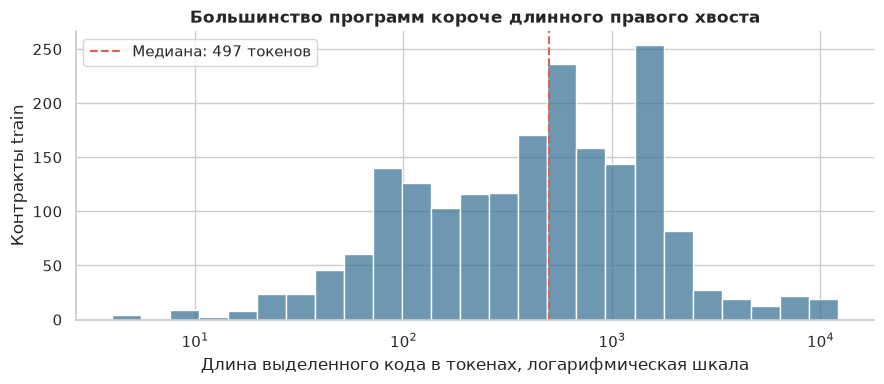

In [25]:
# Короткий график длины кода для объяснения основной особенности на презентации.
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(train.n_tokens, bins=25, log_scale=True, color="#3d7598", ax=ax)
ax.axvline(train.n_tokens.median(), color="#d86152", linestyle="--", label="Медиана: 497 токенов")
ax.set(title="Большинство программ короче длинного правого хвоста",
       xlabel="Длина выделенного кода в токенах, логарифмическая шкала", ylabel="Контракты train")
ax.legend()
fig.tight_layout()
plt.show()


### Выводы по распределениям и выбросам

Анализ выполнен на 1 926 контрактах train. Есть особенности, которые нужно учитывать при подготовке признаков и выборе модели.

1. **Размеры контрактов сильно различаются.** Медианная длина составляет 497 токенов, средняя - около 904, 99-й процентиль - около 8 524, максимум - 12 099. Небольшая доля длинных контрактов увеличивает среднее. Поэтому типичный размер лучше описывать медианой и квантилями, а распределение длины показывать в нелинейном масштабе. Для будущей нейросетевой модели потребуется оценить, сколько кода теряется при ограничении длины входа.

2. **Операции, важные для анализа слабостей, встречаются редко.** Счётчик `низкоуровневых вызовов` равен нулю примерно у 85% контрактов, `tx.origin` - у 96%, `delegatecall` - у 99%. Здесь ноль означает, что конструкция не найдена в выделенном коде. При анализе таких признаков полезно сравнивать долю объектов с наличием операции и число операций среди этих объектов. Связь с метками слабостей проверяется в следующем разделе.

3. **Формальный IQR-флаг требует проверки.** Для `низкоуровневых вызовов`, `tx.origin` и ряда других счётчиков оба квартиля равны нулю. Поэтому правило `Q3 + 1.5·IQR` помечает любое ненулевое значение как выброс. Удаление этих объектов убрало бы именно редкие операции, которые мы хотим исследовать. По длине кода правило отмечает 92 контракта, около 4,8% train. Сам размер ещё не даёт основания считать такой объект ошибочным.

4. **В текущем эксперименте сохраняем наблюдения и исходные значения счётчиков.** IQR-флаги используем для просмотра необычных примеров, включая таблицу самых длинных контрактов. При дальнейшем сравнении моделей нужно учитывать правые хвосты распределений и многочисленные нули, а полезность каждого счётчика оценивать по его связи с известными целевыми метками.


## 6. Связи с известными метками
Используется отдельная маска для каждого класса. Корреляции описательные: групповые зависимости, различия источников и исторические версии ограничивают их обобщение.

### Что проверяем в этом разделе

Для каждого SWC сравниваем признаки контрактов с известными метками 0 и 1 в train.
`associations` — сводка для 8 классов и 14 признаков, всего 112 сочетаний.
`class_pivots` содержит описательные статистики отдельно для двух меток, всего 224 строки.
Все эти DataFrame вычисляются в памяти из `train` и `train_y`.

На тепловой карте Spearman показывает направление и силу монотонной связи счётчика
с меткой. Положительное значение означает, что большие значения чаще встречаются
у положительных примеров. Число известных меток и количество положительных примеров
нужно читать вместе с корреляцией. P-values и поправка BH используются как
описательные показатели из-за связанных групп и неоднородных источников.


In [26]:
def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    ranked = values[order] * len(values) / np.arange(1, len(values) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1].clip(0, 1)
    result = np.empty(len(values))
    result[order] = ranked
    return result


In [27]:
associations, class_pivots = [], []
for swc in CORE_SWCS:
    y = train_y[f"swc_{swc}"]
    known = y.notna()
    for feature in FEATURES:
        x, yy = train.loc[known, feature].astype(float), y[known].astype(int)
        correlation, pvalue = (np.nan, np.nan)
        pb, pbp = (np.nan, np.nan)
        if x.nunique() > 1 and yy.nunique() == 2:
            correlation, pvalue = spearmanr(x, yy)
            pb, pbp = pointbiserialr(yy, x)
        associations.append({"swc": swc, "feature": feature, "n_known_train": len(x),
                             "positive_n": int(yy.eq(1).sum()), "negative_n": int(yy.eq(0).sum()),
                             "spearman_rho": correlation, "spearman_p_descriptive": pvalue,
                             "point_biserial_r": pb, "point_biserial_p_descriptive": pbp})
        for value in (0, 1):
            selected = x[yy.eq(value)]
            class_pivots.append({"swc": swc, "feature": feature, "label": value,
                                 "n": len(selected), "median": selected.median(),
                                 "q25": selected.quantile(.25), "q75": selected.quantile(.75),
                                 "mean": selected.mean()})

In [28]:
associations = pd.DataFrame(associations)
valid = associations.spearman_p_descriptive.notna()
associations.loc[valid, "spearman_q_bh_descriptive"] = bh_adjust(associations.loc[valid, "spearman_p_descriptive"])
pd.DataFrame(class_pivots)

,swc,feature,label,n,median,q25,q75,mean
0,101,n_tokens,0,201,119.0,57.0,211.0,212.029851
1,101,n_tokens,1,447,399.0,201.0,644.0,491.503356
2,101,n_code_lines,0,201,22.0,12.0,41.0,33.024876
3,101,n_code_lines,1,447,61.0,33.0,101.5,74.000000
4,101,n_functions,0,201,3.0,2.0,6.0,4.945274
...,...,...,...,...,...,...,...,...
219,128,n_timestamp,1,15,0.0,0.0,0.0,0.600000
220,128,n_selfdestruct,0,368,0.0,0.0,0.0,0.130435
221,128,n_selfdestruct,1,15,0.0,0.0,0.0,0.066667
222,128,n_assembly,0,368,0.0,0.0,0.0,0.152174


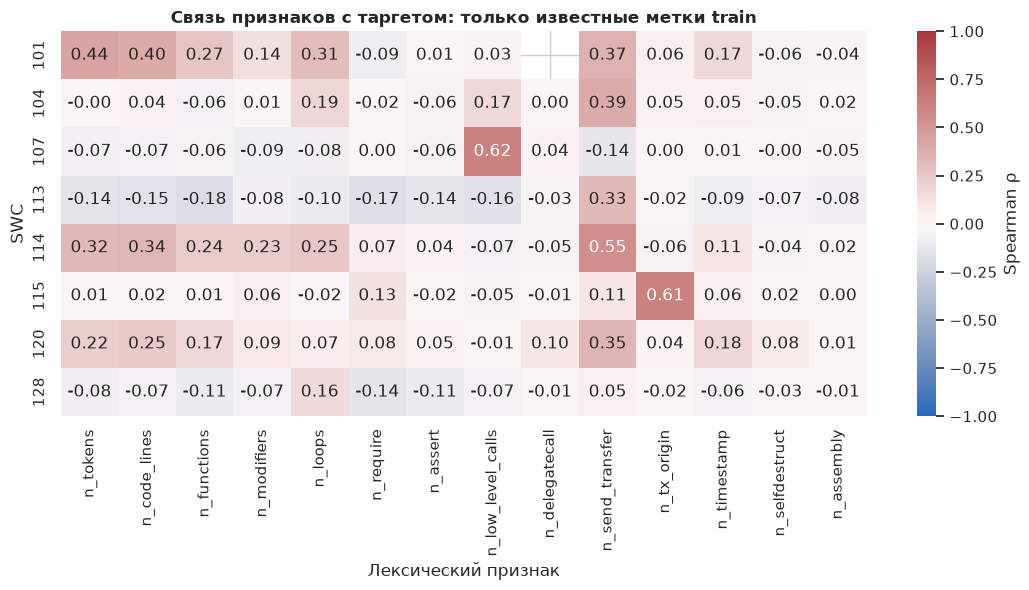

In [29]:
fig, ax = plt.subplots(figsize=(13, 5))
heat = associations.pivot(index="swc", columns="feature", values="spearman_rho").reindex(columns=FEATURES)
sns.heatmap(heat, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set(title="Связь признаков с таргетом: только известные метки train", xlabel="Лексический признак", ylabel="SWC")
plt.show()

In [30]:
display(associations.loc[
    associations.spearman_rho.abs().nlargest(15).index,
    ["swc", "feature", "n_known_train", "positive_n", "negative_n", "spearman_rho"]
].round({"spearman_rho": 3}))


,swc,feature,n_known_train,positive_n,negative_n,spearman_rho
35,107,n_low_level_calls,941,75,866,0.616
80,115,n_tx_origin,1024,21,1003,0.610
65,114,n_send_transfer,730,283,447,0.547
0,101,n_tokens,648,447,201,0.443
1,101,n_code_lines,648,447,201,0.402
23,104,n_send_transfer,1072,205,867,0.394
9,101,n_send_transfer,648,447,201,0.365
93,120,n_send_transfer,1062,180,882,0.346
57,114,n_code_lines,730,283,447,0.337
51,113,n_send_transfer,1028,228,800,0.330


In [124]:
# Для редких дискретных операций сравниваем доли наличия внутри каждой метки.
pairs = [(107, "n_low_level_calls"), (115, "n_tx_origin"),
         (120, "n_timestamp"), (128, "n_loops")]
presence_rows = []
for swc, feature in pairs:
    known = train_y[f"swc_{swc}"].notna()
    presence_frame = pd.DataFrame({
        "label": train_y.loc[known, f"swc_{swc}"].astype(int),
        "present": train.loc[known, feature].gt(0),
        "group_id": train.loc[known, "group_id"],
    })
    for label, part in presence_frame.groupby("label"):
        presence_rows.append({
            "swc": swc, "feature": feature, "label": label,
            "with_operation": int(part.present.sum()), "n_known": len(part),
            "fraction": part.present.mean(), "n_groups": part.group_id.nunique(),
        })
presence_summary = pd.DataFrame(presence_rows)
presence_summary

,swc,feature,label,with_operation,n_known,fraction,n_groups
0,107,n_low_level_calls,0,73,866,0.084296,673
1,107,n_low_level_calls,1,66,75,0.880000,54
2,115,n_tx_origin,0,30,1003,0.029910,710
3,115,n_tx_origin,1,20,21,0.952381,15
4,120,n_timestamp,0,191,882,0.216553,631
5,120,n_timestamp,1,79,180,0.438889,144
6,128,n_loops,0,188,368,0.510870,285
7,128,n_loops,1,15,15,1.000000,15


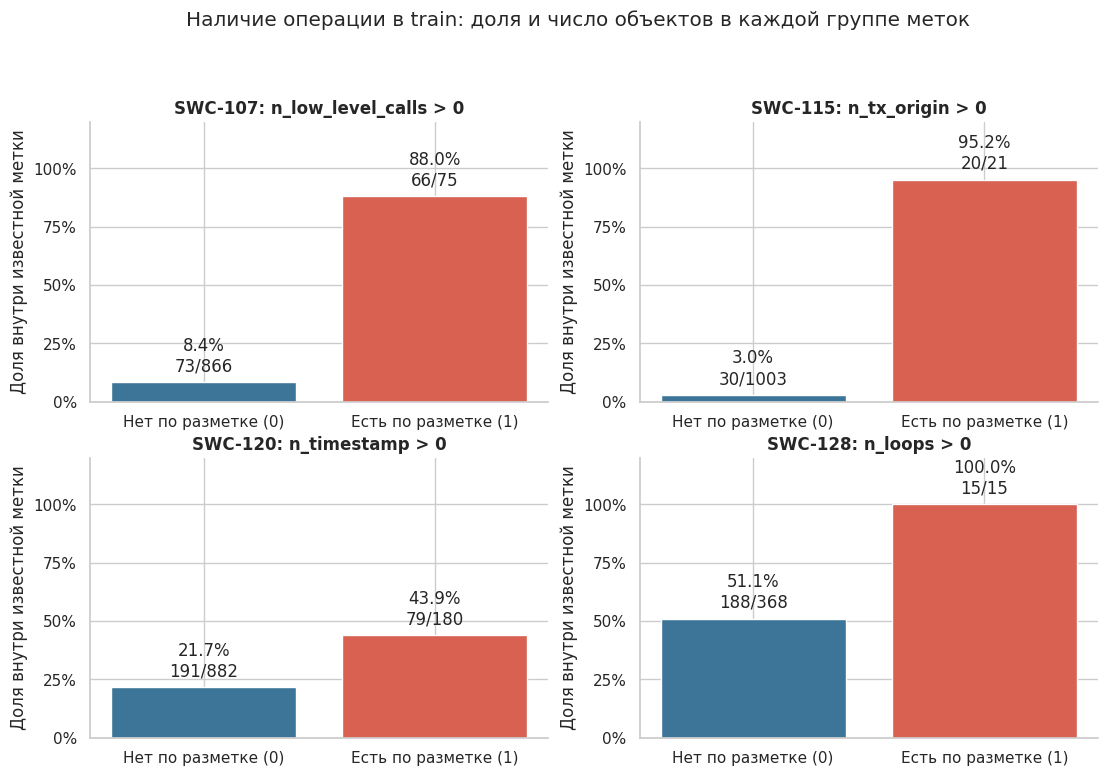

In [125]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (swc, feature) in zip(axes.flat, pairs):
    part = presence_summary[presence_summary.swc.eq(swc)].sort_values("label")
    bars = ax.bar([0, 1], part.fraction, color=["#3d7598", "#d86152"])
    labels_on_bars = [
        f"{row.fraction:.1%}\n{row.with_operation}/{row.n_known}"
        for row in part.itertuples(index=False)
    ]
    ax.bar_label(bars, labels=labels_on_bars, padding=5)
    ax.set_xticks([0, 1], labels=["Нет по разметке (0)", "Есть по разметке (1)"])
    ax.set_yticks([0, .25, .5, .75, 1], labels=["0%", "25%", "50%", "75%", "100%"])
    ax.set(title=f"SWC-{swc}: {feature} > 0", ylabel="Доля внутри известной метки", ylim=(0, 1.2))
fig.suptitle("Наличие операции в train: доля и число объектов в каждой группе меток", y=1.02)
plt.show()


### Проверка зависимости от источника

Для SWC-115 и SWC-120 проверяем, сохраняется ли различие внутри отдельных источников.
Источник берём из исходных проверок именно данного SWC по `assessment_rows`.
В сравнении показаны источники хотя бы с тремя положительными и тремя отрицательными
контрактами train. Это ограничение отображения таблицы. Общие графики выше используют
все известные метки. Один контракт может встречаться в нескольких источниках.


In [126]:
source_rows = []
for swc, feature in [(115, "n_tx_origin"), (120, "n_timestamp")]:
    known_ids = train_y.index[train_y[f"swc_{swc}"].notna()]
    for entity_id in known_ids:
        contract = train.loc[entity_id]
        row_numbers = [int(value) for value in contract.assessment_rows.split("|")]
        checks = assessments.iloc[row_numbers]
        origins = checks.loc[checks.swc.eq(str(swc)), "dataset"].unique()
        for dataset in origins:
            source_rows.append({
                "swc": swc, "dataset": dataset, "entity_id": entity_id,
                "label": int(train_y.at[entity_id, f"swc_{swc}"]),
                "present": contract[feature] > 0,
            })
source_observations = pd.DataFrame(source_rows)
source_summary = source_observations.groupby(["swc", "dataset", "label"]).agg(
    n_known=("entity_id", "size"), fraction=("present", "mean"),
).reset_index()
source_support = source_summary.pivot(index=["swc", "dataset"], columns="label", values="n_known")
source_support = source_support.rename(columns={0: "n_negative", 1: "n_positive"})
source_rates = source_summary.pivot(index=["swc", "dataset"], columns="label", values="fraction")
source_rates = source_rates.rename(columns={0: "fraction_negative", 1: "fraction_positive"})
source_comparison = source_support.join(source_rates)
source_comparison = source_comparison.loc[
    source_comparison.n_negative.ge(3) & source_comparison.n_positive.ge(3)
].copy()
source_comparison[["n_negative", "n_positive"]] = source_comparison[["n_negative", "n_positive"]].astype(int)
source_comparison


label           n_negative  n_positive  fraction_negative  fraction_positive
swc dataset                                                                 
115 CodeSmells         366           5           0.002732           0.800000
    Doublade            20           9           1.000000           1.000000
    Zeus               638           3           0.012539           1.000000
120 CodeSmells         343          22           0.358601           0.181818
    NPChecker           27           4           0.148148           0.250000
    Zeus               540          96           0.127778           0.614583

### Выводы и дальнейшие действия

**Счётчики содержат сигнал, но его сила различается по классам и источникам.**
Тепловая карта нужна как обзор всех 112 связей. Для выбранных редких операций график
долей понятнее boxplot — при многочисленных нулях медианы совпадают, а доли и
знаменатели сразу показывают различие и объём свидетельств.

- **Reentrancy.** Низкоуровневый вызов присутствует у 66 из 75 положительных
  контрактов (88%) и у 73 из 866 отрицательных (8,4%). Spearman равен примерно 0,616.
  Если предупреждать о reentrancy при любом таком вызове, на этих известных train-метках
  получим 66 совпадений с положительной оценкой и 73 ложных предупреждения.
  Ещё 9 положительных примеров не содержат найденного низкоуровневого вызова.
  Это обосновывает анализ контекста вызовов, порядка изменения состояния и защиты
  от повторного входа, а также отдельный просмотр этих девяти случаев.

- **Авторизация через `tx.origin`.** Упоминание есть у 20 из 21 положительных
  контрактов (95,2%) и у 30 из 1 003 отрицательных (3%). Однако внутри Doublade
  оно встречается у всех 9 положительных и всех 20 отрицательных примеров.
  Следовательно, сам факт упоминания в этом источнике не разделяет классы.
  Для улучшения представления нужен контекст использования `tx.origin` в авторизации.
  Поддержка всего 21 положительного контракта дополнительно ограничивает вывод.

- **Слабая случайность.** Обращения к времени найдены у 79 из 180 положительных
  контрактов (43,9%) и у 191 из 882 отрицательных (21,7%). При этом внутри CodeSmells
  доли равны 4/22 (18,2%) и 123/343 (35,9%) — направление различия меняется.
  Общую ассоциацию нельзя считать устойчивым правилом для всех источников.
  Нужно проверять определения исходных свойств, контекст использования времени
  и перенос между источниками.

- **DoS по лимиту газа.** Цикл найден во всех 15 положительных train-примерах,
  но также у 188 из 368 отрицательных (51,1%). Предупреждение по одному наличию цикла
  даст много ложных сигналов. Следующий содержательный признак должен учитывать
  условия и объём работы цикла. Для оценки этого класса нужны дополнительные
  независимые размеченные примеры.

**Применение к проекту.** Найденные связи задают гипотезы для дальнейшей работы.
Счётчики операций стоит сравнивать с представлениями, учитывающими контекст и структуру
кода. Устойчивость проверяется между источниками и группами похожих реализаций.
Корреляции и доли здесь описывают исследовательскую часть и имеющиеся оценки.


## 7. Попарные распределения и корреляции
Pairplot использует пять выбранных счётчиков в log1p-шкале для известных SWC-107 в train. Ниже график строится через `sns.pairplot`.

### Как читать связи между признаками

Матрица ниже рассчитана по всем 1 926 контрактам train и показывает связь признаков
друг с другом. Цветовая шкала зафиксирована от −1 до 1 с нулём в центре, а числа
позволяют различать сильные и слабые связи.

Pairplot рассматривает только 941 контракт с известной SWC-107 — 866 отрицательных
и 75 положительных. На диагонали гистограммы нормированы отдельно внутри каждой
метки, чтобы сравнивать формы распределений при разном числе объектов. Точки ниже
диагонали показывают совместные значения пар признаков. Координаты преобразованы
через `log1p`, что сохраняет нули и сжимает длинные хвосты.


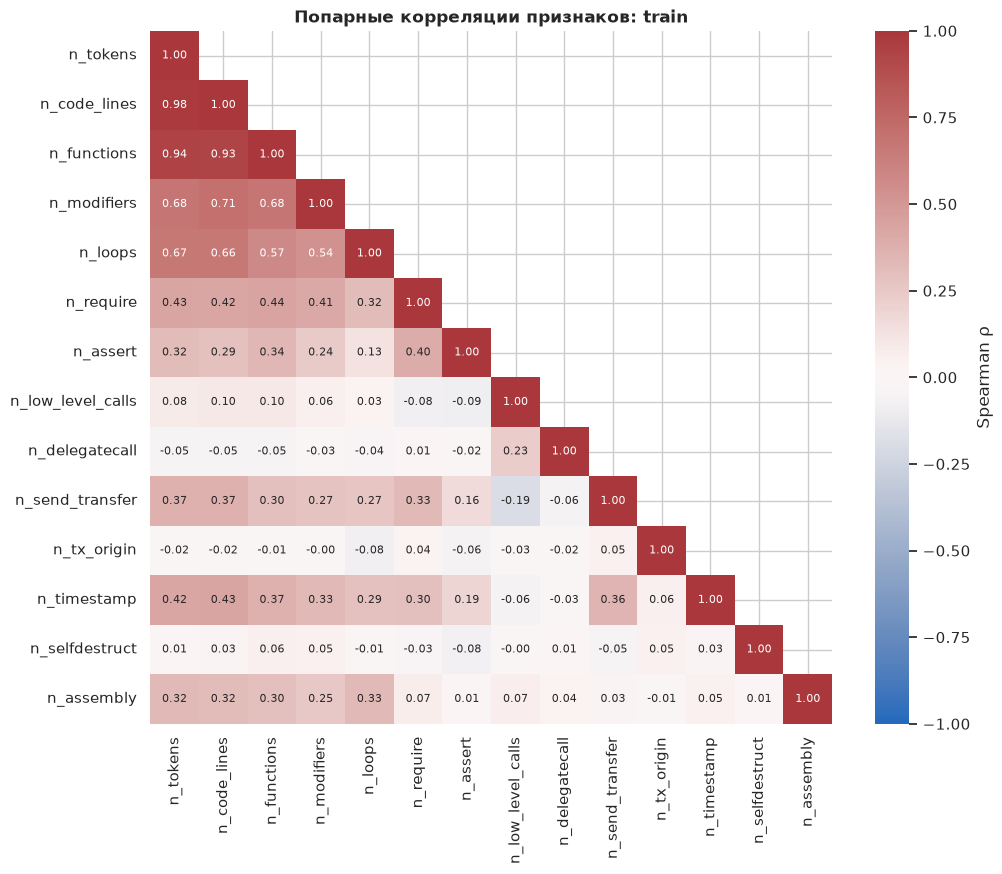

In [33]:
correlation = train[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, mask=np.triu(np.ones(correlation.shape, dtype=bool), k=1), cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Попарные корреляции признаков: train")
plt.show()

In [127]:
pair_features = ["n_tokens", "n_functions", "n_loops", "n_require", "n_low_level_calls"]
y_re = train_y.swc_107
pair_data = train.loc[y_re.notna(), pair_features].copy()
pair_data[pair_features] = np.log1p(pair_data[pair_features])
pair_data["Reentrancy"] = y_re[y_re.notna()].map({0: "нет по оценке", 1: "есть по оценке"})

if len(pair_data) > 1200:
    pair_data = pair_data.sample(1200, random_state=42)
hue_order = ["нет по оценке", "есть по оценке"]
print("Известные SWC-107 в train:")
y_re.dropna().map({0: hue_order[0], 1: hue_order[1]}).value_counts().reindex(hue_order)

Известные SWC-107 в train:


swc_107
нет по оценке     866
есть по оценке     75
Name: count, dtype: int64

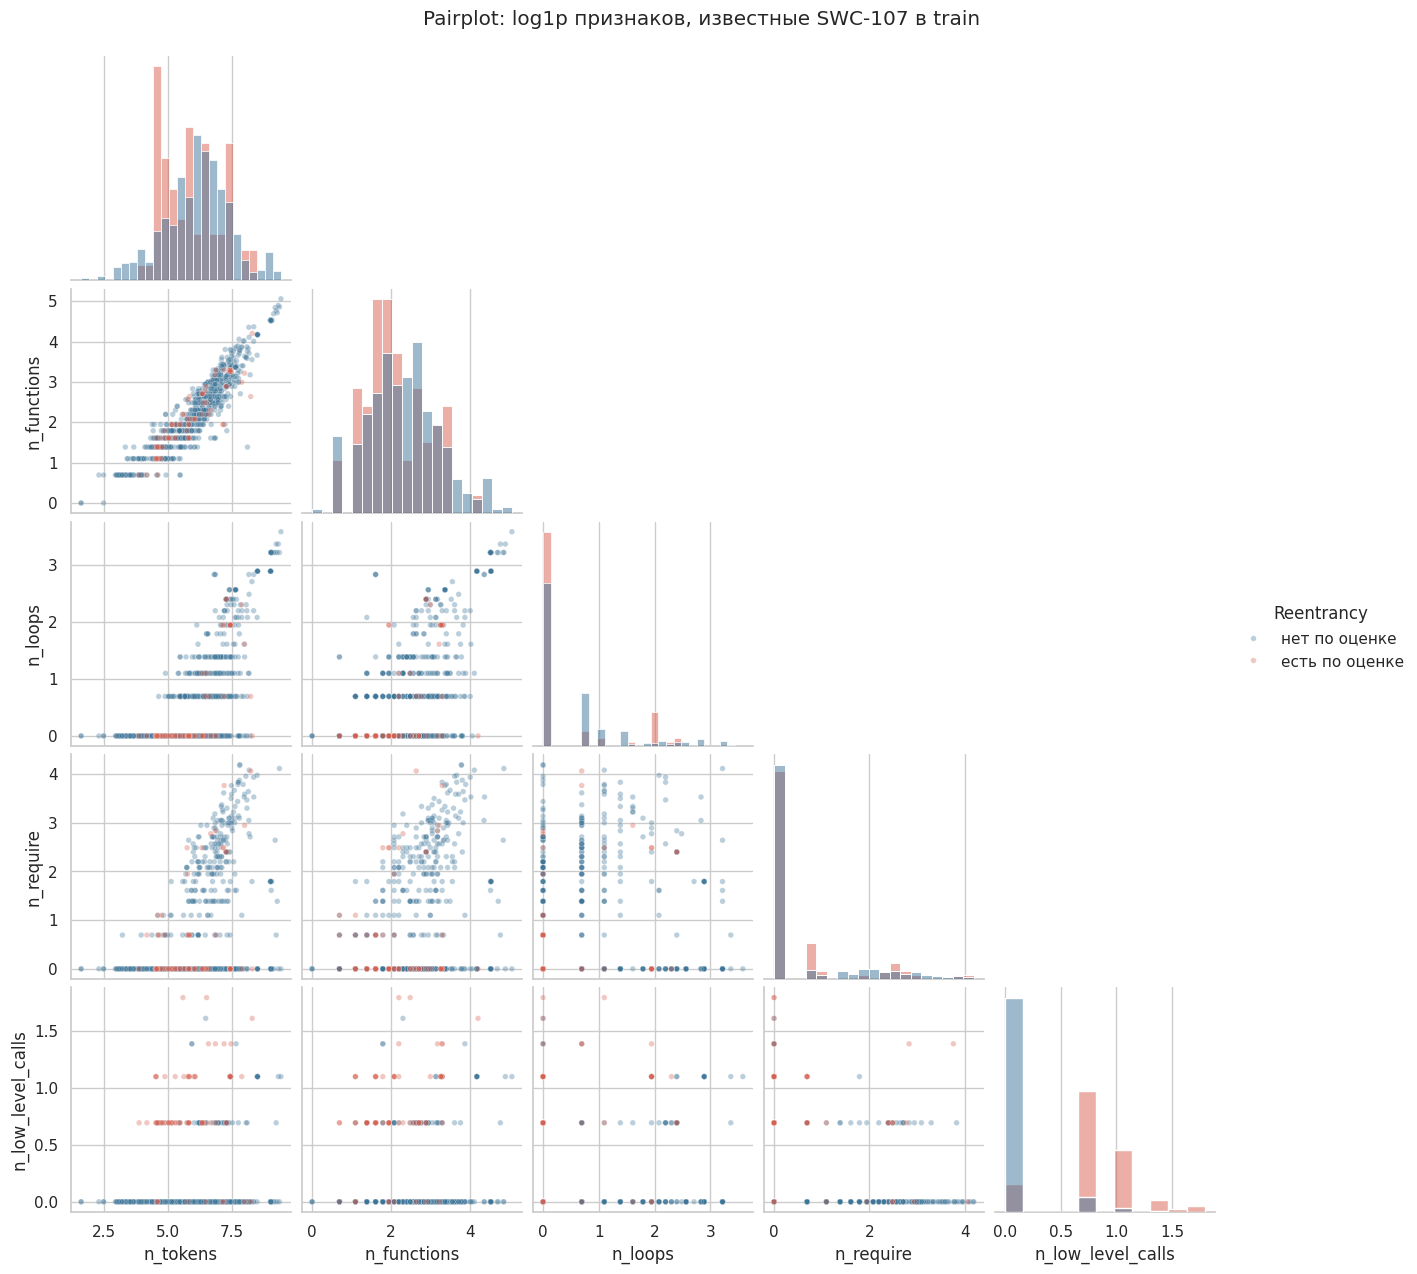

In [128]:
pair_data = pair_data.sort_values("Reentrancy", ascending=False)
grid = sns.pairplot(pair_data, hue="Reentrancy", hue_order=hue_order, vars=pair_features, corner=True, diag_kind="hist", diag_kws={"stat": "density", "common_norm": False}, grid_kws={"diag_sharey": False}, plot_kws={"alpha": .35, "s": 16}, palette=["#3d7598", "#d86152"])
grid.figure.suptitle("Pairplot: log1p признаков, известные SWC-107 в train", y=1.02)
plt.show()


In [129]:
correlation

,n_tokens,n_code_lines,n_functions,n_modifiers,n_loops,n_require,n_assert,n_low_level_calls,n_delegatecall,n_send_transfer,n_tx_origin,n_timestamp,n_selfdestruct,n_assembly
n_tokens,1.000000,0.983115,0.944146,0.679151,0.667028,0.433646,0.318744,0.080048,-0.053641,0.369133,-0.024724,0.424138,0.009181,0.322351
n_code_lines,0.983115,1.000000,0.934972,0.710116,0.664893,0.423323,0.290816,0.096948,-0.054539,0.373010,-0.017334,0.432335,0.029506,0.319397
n_functions,0.944146,0.934972,1.000000,0.675664,0.570359,0.437661,0.337372,0.101552,-0.053599,0.298957,-0.005394,0.367638,0.056166,0.303609
n_modifiers,0.679151,0.710116,0.675664,1.000000,0.538054,0.409723,0.242970,0.056101,-0.029768,0.274755,-0.000805,0.328630,0.052440,0.254683
n_loops,0.667028,0.664893,0.570359,0.538054,1.000000,0.318812,0.132129,0.033288,-0.038633,0.271766,-0.079488,0.291164,-0.007867,0.330085
n_require,0.433646,0.423323,0.437661,0.409723,0.318812,1.000000,0.397357,-0.082935,0.006679,0.330691,0.036441,0.298919,-0.034667,0.074673
n_assert,0.318744,0.290816,0.337372,0.242970,0.132129,0.397357,1.000000,-0.089739,-0.024754,0.160870,-0.061746,0.192255,-0.077649,0.005945
n_low_level_calls,0.080048,0.096948,0.101552,0.056101,0.033288,-0.082935,-0.089739,1.000000,0.229002,-0.193777,-0.029932,-0.055748,-0.004689,0.065144
n_delegatecall,-0.053641,-0.054539,-0.053599,-0.029768,-0.038633,0.006679,-0.024754,0.229002,1.000000,-0.055394,-0.018861,-0.026342,0.012136,0.035727
n_send_transfer,0.369133,0.373010,0.298957,0.274755,0.271766,0.330691,0.160870,-0.193777,-0.055394,1.000000,0.053012,0.356996,-0.048496,0.027302


In [130]:
# Каждая пара признаков учитывается один раз, диагональ исключена.
lower_triangle = correlation.where(np.tril(np.ones(correlation.shape, dtype=bool), k=-1))
correlation_pairs = lower_triangle.stack().dropna().rename("spearman_rho").reset_index()
correlation_pairs.columns = ["feature_a", "feature_b", "spearman_rho"]
strongest_pairs = correlation_pairs.loc[correlation_pairs.spearman_rho.abs().nlargest(10).index]
strongest_pairs


,feature_a,feature_b,spearman_rho
0,n_code_lines,n_tokens,0.983115
1,n_functions,n_tokens,0.944146
2,n_functions,n_code_lines,0.934972
4,n_modifiers,n_code_lines,0.710116
3,n_modifiers,n_tokens,0.679151
5,n_modifiers,n_functions,0.675664
6,n_loops,n_tokens,0.667028
7,n_loops,n_code_lines,0.664893
8,n_loops,n_functions,0.570359
9,n_loops,n_modifiers,0.538054


### Проверка связи с меткой при сопоставимой длине кода

Делим весь train на четыре группы по квартилям `n_tokens`. Границы определяются
без использования меток. Затем внутри каждой группы сравниваем долю контрактов
с операцией среди известных меток 0 и 1 для SWC-107 и SWC-128. Подписи показывают
долю и числитель/знаменатель. Это описательная проверка чувствительности к размеру
кода, при которой другие различия между объектами и источниками сохраняются.


In [131]:
size_edges = train.n_tokens.quantile([.25, .5, .75]).to_numpy()
size_names = ["Q1", "Q2", "Q3", "Q4"]
size_bins = pd.cut(train.n_tokens, bins=[-np.inf, *size_edges, np.inf], labels=size_names)
display(pd.Series(size_edges, index=["25%", "50%", "75%"], name="Границы n_tokens").to_frame())

size_summaries = []
for swc, feature in [(107, "n_low_level_calls"), (128, "n_loops")]:
    known = train_y[f"swc_{swc}"].notna()
    size_frame = pd.DataFrame({
        "size_bin": size_bins[known],
        "label": train_y.loc[known, f"swc_{swc}"].astype(int),
        "present": train.loc[known, feature].gt(0),
    })
    size_summary = size_frame.groupby(["size_bin", "label"], observed=True).agg(
        with_operation=("present", "sum"), n_known=("present", "size"),
        fraction=("present", "mean"),
    ).reset_index()
    size_summary["swc"] = swc
    size_summaries.append(size_summary)
size_comparison = pd.concat(size_summaries, ignore_index=True)
size_comparison

,Границы n_tokens
25%,157.00
50%,497.00
75%,1142.75


,size_bin,label,with_operation,n_known,fraction,swc
0,Q1,0,4,165,0.024242,107
1,Q1,1,21,24,0.875000,107
2,Q2,0,11,272,0.040441,107
3,Q2,1,22,23,0.956522,107
4,Q3,0,22,240,0.091667,107
5,Q3,1,11,12,0.916667,107
6,Q4,0,36,189,0.190476,107
7,Q4,1,12,16,0.750000,107
8,Q1,0,3,26,0.115385,128
9,Q1,1,6,6,1.000000,128


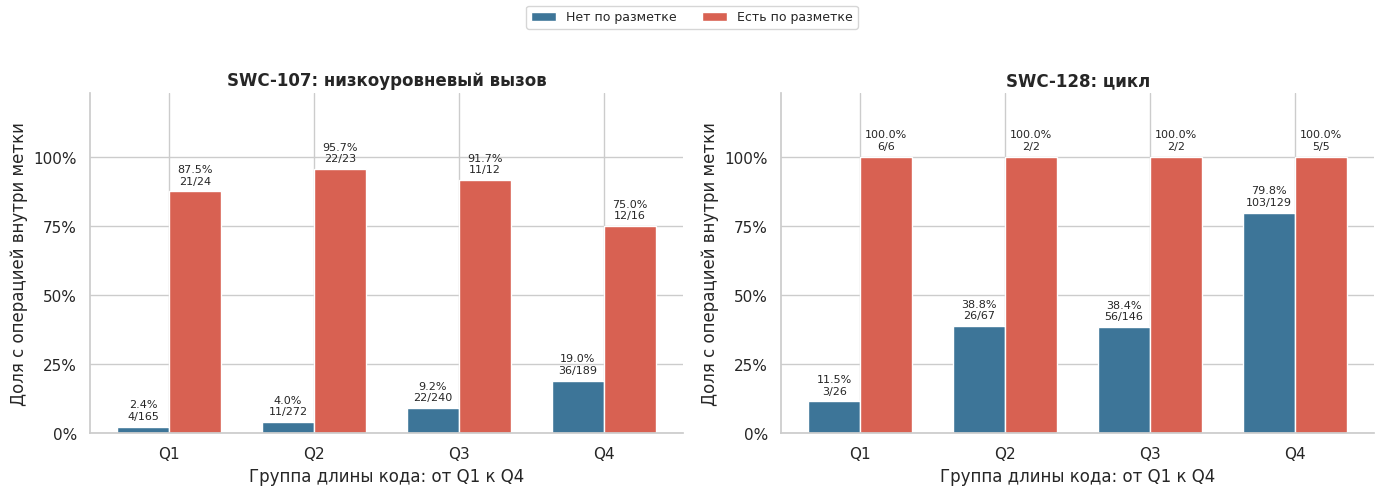

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, swc in zip(axes, [107, 128]):
    for label, color in [(0, "#3d7598"), (1, "#d86152")]:
        part = size_comparison[size_comparison.swc.eq(swc) & size_comparison.label.eq(label)]
        positions = part.size_bin.cat.codes.to_numpy() + (label - .5) * .36
        bars = ax.bar(positions, part.fraction, width=.36, color=color,
                      label="Нет по разметке" if label == 0 else "Есть по разметке")
        captions = [f"{row.fraction:.1%}\n{int(row.with_operation)}/{row.n_known}"
                    for row in part.itertuples(index=False)]
        ax.bar_label(bars, labels=captions, padding=4, fontsize=8)
    operation = "низкоуровневый вызов" if swc == 107 else "цикл"
    ax.set(title=f"SWC-{swc}: {operation}", xlabel="Группа длины кода: от Q1 к Q4",
           ylabel="Доля с операцией внутри метки", ylim=(0, 1.23))
    ax.set_xticks(np.arange(4), labels=size_names)
    ax.set_yticks([0, .25, .5, .75, 1], labels=["0%", "25%", "50%", "75%", "100%"])
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, .9))
plt.show()


### Выводы по попарным связям и их применение

1. **Число токенов, строк и функций во многом отражает общий объём кода.**
   Spearman для токенов и строк равен 0,983, токенов и функций — 0,944,
   строк и функций — 0,935. Это основание проверить избыточность представления
   в будущей модели на числовых признаках. На validation стоит сравнить варианты
   с одним показателем объёма и со всеми тремя. Эту избыточность учитываем при выборе представления кода на следующих этапах.

2. **Часть счётчиков связана с размером контракта.** Например, число циклов
   коррелирует с числом токенов на уровне 0,667. При оценке счётчика важно проверить,
   сохраняется ли его связь с меткой среди контрактов сопоставимой длины.
   Добавленная квартильная проверка позволяет сделать это на текущем train.

3. **Сигнал низкоуровневых вызовов для reentrancy сохраняется во всех четырёх
   группах длины.** Среди положительных примеров вызов присутствует у 75–95,7%,
   среди отрицательных — у 2,4–19,0%. Грубый учёт размера сохраняет различие.
   Это поддерживает дальнейшее исследование контекста внешних вызовов.
   Одновременно pairplot показывает перекрывающиеся распределения. В известной
   SWC-107 части медиана длины положительных контрактов составляет 327 токенов,
   отрицательных — 495. Другие факторы, включая происхождение и варианты кода,
   требуют отдельной проверки.

4. **Для циклов влияние размера особенно заметно среди отрицательных SWC-128.**
   Доля контрактов с циклом увеличивается с 3/26 (11,5%) в Q1 до 103/129 (79,8%)
   в Q4. Во всех 15 положительных примерах циклы присутствуют, но в отдельных
   квартилях положительных объектов всего по два. Наличие цикла даёт много
   предупреждений на больших контрактах. Для следующего представления нужны
   признаки условий и объёма работы цикла, а устойчивость результата требует
   дополнительных независимых примеров.

**Дальнейшее действие для проекта** — сравнить на validation наборы числовых
признаков с учётом избыточных показателей объёма, затем проверить относительные
счётчики и признаки контекста. Для относительных счётчиков отдельно нужна проверка
коротких контрактов, где деление на длину может усиливать случайные различия.
Выбор представления должен опираться на качество отложенной оценки. Матрица,
pairplot и квартильные доли здесь служат для постановки этих экспериментов.


## 8. Совместная встречаемость и источники смещения
Для совместных меток показывается знаменатель: число контрактов, у которых известны оба класса. Источники у одного контракта могут пересекаться. Семейство pragma не равно фактически использованной версии компилятора.

### Как читать совместные метки

В этом разделе рассматриваются восемь выбранных SWC и только train.
Каждую пару оцениваем среди контрактов, у которых известны обе метки.
Например, `203/611` означает, что у 203 из 611 таких контрактов обе оценки
положительные. Для разных пар знаменатели различаются. Число на графике описывает
наблюдаемый корпус и его схему проверок.

На диагонали повторяется один класс, поэтому диагональ и симметричная половина
матрицы скрыты. Полные исходные количества остаются в следующих таблицах.


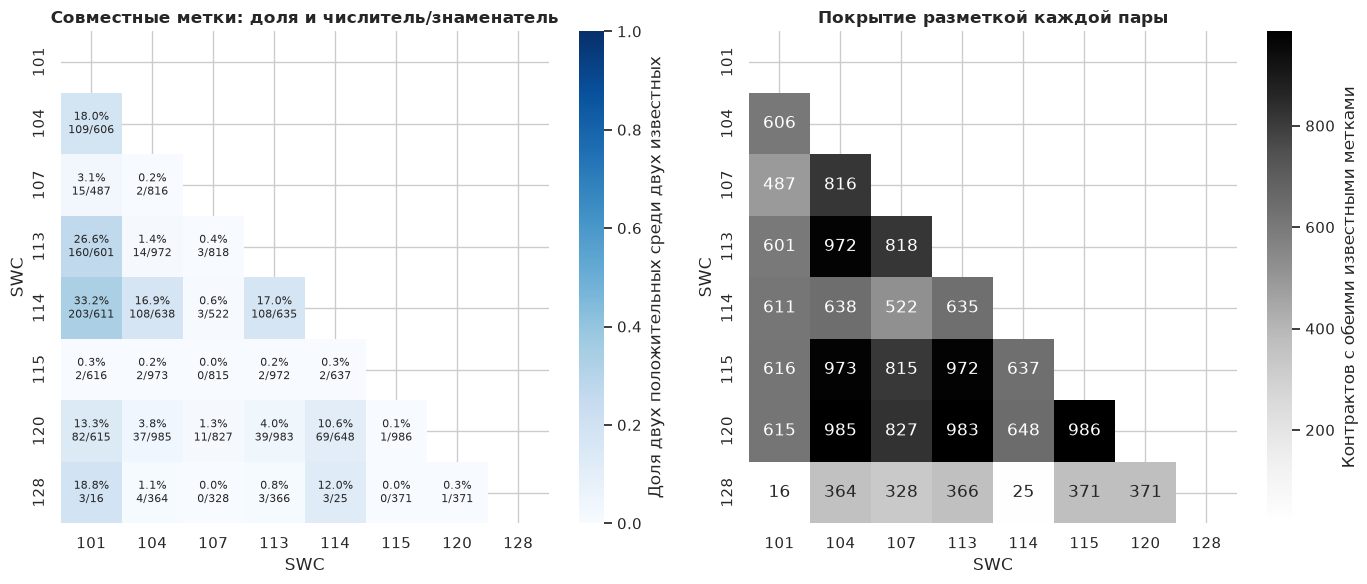

In [38]:
co_positive = pd.DataFrame(index=CORE_SWCS, columns=CORE_SWCS, dtype=float)
co_known = co_positive.copy()
co_fraction = co_positive.copy()

for a in CORE_SWCS:
    for b in CORE_SWCS:
        ya, yb = train_y[f"swc_{a}"], train_y[f"swc_{b}"]
        known = ya.notna() & yb.notna()
        positive = int((ya[known].eq(1) & yb[known].eq(1)).sum())
        co_positive.at[a, b] = positive
        co_known.at[a, b] = int(known.sum())
        co_fraction.at[a, b] = positive / known.sum() if known.any() else np.nan

# В каждой клетке свой знаменатель — оба класса должны быть известны.
co_annotations = pd.DataFrame("", index=CORE_SWCS, columns=CORE_SWCS)
for a in CORE_SWCS:
    for b in CORE_SWCS:
        if co_known.at[a, b] > 0:
            co_annotations.at[a, b] = (
                f"{co_fraction.at[a, b]:.1%}\n"
                f"{int(co_positive.at[a, b])}/{int(co_known.at[a, b])}"
            )
            
pair_mask = np.triu(np.ones(co_fraction.shape, dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(co_fraction, mask=pair_mask, annot=co_annotations, fmt="", cmap="Blues",
            vmin=0, vmax=1, annot_kws={"fontsize": 8}, ax=axes[0],
            cbar_kws={"label": "Доля двух положительных среди двух известных"})
sns.heatmap(co_known, mask=pair_mask, annot=True, fmt=".0f", cmap="Greys", ax=axes[1],
            cbar_kws={"label": "Контрактов с обеими известными метками"})
axes[0].set_title("Совместные метки: доля и числитель/знаменатель")
axes[1].set_title("Покрытие разметкой каждой пары")
for ax in axes:
    ax.set(xlabel="SWC", ylabel="SWC")
fig.tight_layout()
plt.show()


In [39]:
print(co_positive)
print(co_known)

       101    104   107    113    114   115    120   128
101  447.0  109.0  15.0  160.0  203.0   2.0   82.0   3.0
104  109.0  205.0   2.0   14.0  108.0   2.0   37.0   4.0
107   15.0    2.0  75.0    3.0    3.0   0.0   11.0   0.0
113  160.0   14.0   3.0  228.0  108.0   2.0   39.0   3.0
114  203.0  108.0   3.0  108.0  283.0   2.0   69.0   3.0
115    2.0    2.0   0.0    2.0    2.0  21.0    1.0   0.0
120   82.0   37.0  11.0   39.0   69.0   1.0  180.0   1.0
128    3.0    4.0   0.0    3.0    3.0   0.0    1.0  15.0
       101     104    107     113    114     115     120    128
101  648.0   606.0  487.0   601.0  611.0   616.0   615.0   16.0
104  606.0  1072.0  816.0   972.0  638.0   973.0   985.0  364.0
107  487.0   816.0  941.0   818.0  522.0   815.0   827.0  328.0
113  601.0   972.0  818.0  1028.0  635.0   972.0   983.0  366.0
114  611.0   638.0  522.0   635.0  730.0   637.0   648.0   25.0
115  616.0   973.0  815.0   972.0  637.0  1024.0   986.0  371.0
120  615.0   985.0  827.0   983.0  648.

In [40]:
core_targets = train_y[[f"swc_{swc}" for swc in CORE_SWCS]]
known_core_count = core_targets.notna().sum(axis=1)
positive_core_count = core_targets.eq(1).sum(axis=1)
coverage_distribution = known_core_count.value_counts().reindex(range(9), fill_value=0).sort_index()

coverage_summary = pd.Series({
    "Контрактов train": len(train),
    "Нет известных меток выбранных SWC": int(known_core_count.eq(0).sum()),
    "Известны все 8 выбранных SWC": int(known_core_count.eq(8).sum()),
    "Есть хотя бы 2 положительные выбранные метки": int(positive_core_count.ge(2).sum()),
    "Все известные выбранные метки отрицательные": int((known_core_count.gt(0) & positive_core_count.eq(0)).sum()),
}, name="Контрактов")
coverage_summary.to_frame()

,Контрактов
Контрактов train,1926
Нет известных меток выбранных SWC,475
Известны все 8 выбранных SWC,8
Есть хотя бы 2 положительные выбранные метки,342
Все известные выбранные метки отрицательные,620


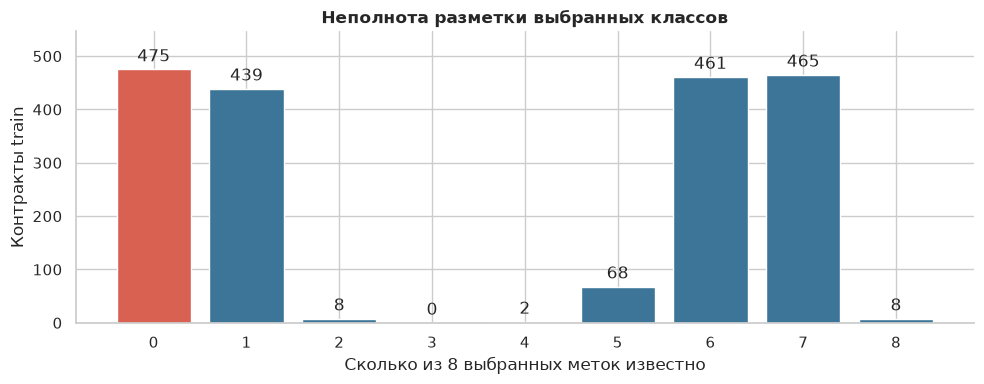

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(coverage_distribution.index, coverage_distribution.values,
              color=["#d86152"] + ["#3d7598"] * 8)
ax.bar_label(bars, padding=3)
ax.set(xlabel="Сколько из 8 выбранных меток известно", ylabel="Контракты train",
       title="Неполнота разметки выбранных классов", xticks=range(9))
ax.set_ylim(0, coverage_distribution.max() * 1.15)
fig.tight_layout()
plt.show()


In [42]:
train["pragma_family"] = train.pragma.str.extract(r"(0\.\d+)", expand=False).fillna("неизвестно")
pragma_counts = train.pragma_family.value_counts().rename_axis("pragma_family").to_frame("contracts")
memberships = train.reset_index()[["entity_id", "datasets", "n_tokens", "n_functions", "n_low_level_calls"]].assign(dataset=lambda d: d.datasets.str.split("|", regex=False)).explode("dataset")
memberships.groupby("dataset")[["n_tokens", "n_functions", "n_low_level_calls"]].agg(["count", "median", "mean"])


n_tokens                      n_functions                    \
                  count  median         mean       count median       mean   
dataset                                                                      
CodeSmells          389   906.0  1221.401028         389   17.0  19.915167   
ContractFuzzer      231   585.0   843.636364         231   11.0  14.562771   
Doublade            197   994.0  2094.421320         197   16.0  26.543147   
EthRacer             77  1040.0  1811.961039          77   18.0  26.532468   
EverEvolvingG       175  1453.0  1483.611429         175   25.0  22.960000   
JiuZhou             100    99.0   111.650000         100    2.0   2.240000   
NPChecker            33   232.0   340.545455          33    5.0   7.030303   
NotSoSmartC          27    91.0   428.703704          27    3.0   6.518519   
SBcurated            90   134.0   309.500000          90    4.0   5.700000   
SWCregistry          83    72.0   108.409639          83    2.0   2.650602   
Zeus                642   285.0   423.819315         642    5.0   7.037383   
eThor               428   283.0   431.273364         428    5.0   6.929907   

               n_low_level_calls                   
                           count median      mean  
dataset                                            
CodeSmells                   389    0.0  0.339332  
ContractFuzzer               231    0.0  0.277056  
Doublade                     197    0.0  0.329949  
EthRacer                      77    0.0  0.272727  
EverEvolvingG                175    0.0  0.074286  
JiuZhou                      100    0.0  0.080000  
NPChecker                     33    0.0  0.242424  
NotSoSmartC                   27    0.0  0.296296  
SBcurated                     90    1.0  0.755556  
SWCregistry                   83    0.0  0.132530  
Zeus                         642    0.0  0.113707  
eThor                        428    0.0  0.102804

### Происхождение кода и происхождение оценки

Таблица `memberships` описывает, в каких источниках встречался код контракта.
Она подходит для сравнения размеров кода. Для баланса отдельного SWC ниже используем
источник именно этой проверки, восстанавливая его по `assessment_rows` из исходного CSV.

`assessed` — число объектов с исходной проверкой источника, `known` — число объектов
с однозначной итоговой меткой после обработки конфликтов. Доля положительных
считается среди `known`. Один объект может иметь проверки из нескольких источников.


In [43]:
label_origin_rows = []
core_swc_strings = [str(swc) for swc in CORE_SWCS]
for entity_id, contract in train.iterrows():
    row_numbers = [int(value) for value in contract.assessment_rows.split("|")]
    checks = assessments.iloc[row_numbers]
    origins = checks.loc[checks.swc.isin(core_swc_strings), ["dataset", "swc"]].drop_duplicates()
    for origin in origins.itertuples(index=False):
        label_origin_rows.append({
            "entity_id": entity_id, "dataset": origin.dataset, "swc": int(origin.swc),
            "label": train_y.at[entity_id, f"swc_{origin.swc}"],
        })
label_origins = pd.DataFrame(label_origin_rows)
source_target = label_origins.groupby(["dataset", "swc"]).agg(
    assessed=("entity_id", "size"), known=("label", "count"),
    positive=("label", lambda values: int(values.eq(1).sum())),
    negative=("label", lambda values: int(values.eq(0).sum())),
).reset_index()
source_target["conflicting"] = source_target.assessed - source_target.known
source_target["positive_fraction_among_known"] = source_target.positive / source_target.known.replace(0, np.nan)
source_target

,dataset,swc,assessed,known,positive,negative,conflicting,positive_fraction_among_known
0,CodeSmells,104,371,364,13,351,7,0.035714
1,CodeSmells,107,320,320,4,316,0,0.012500
2,CodeSmells,113,371,363,3,360,8,0.008264
3,CodeSmells,115,371,371,5,366,0,0.013477
4,CodeSmells,120,365,365,22,343,0,0.060274
5,CodeSmells,128,371,371,8,363,0,0.021563
6,ContractFuzzer,104,30,24,24,0,6,1.000000
7,ContractFuzzer,107,6,6,6,0,0,1.000000
8,ContractFuzzer,120,60,60,60,0,0,1.000000
9,Doublade,104,36,33,31,2,3,0.939394


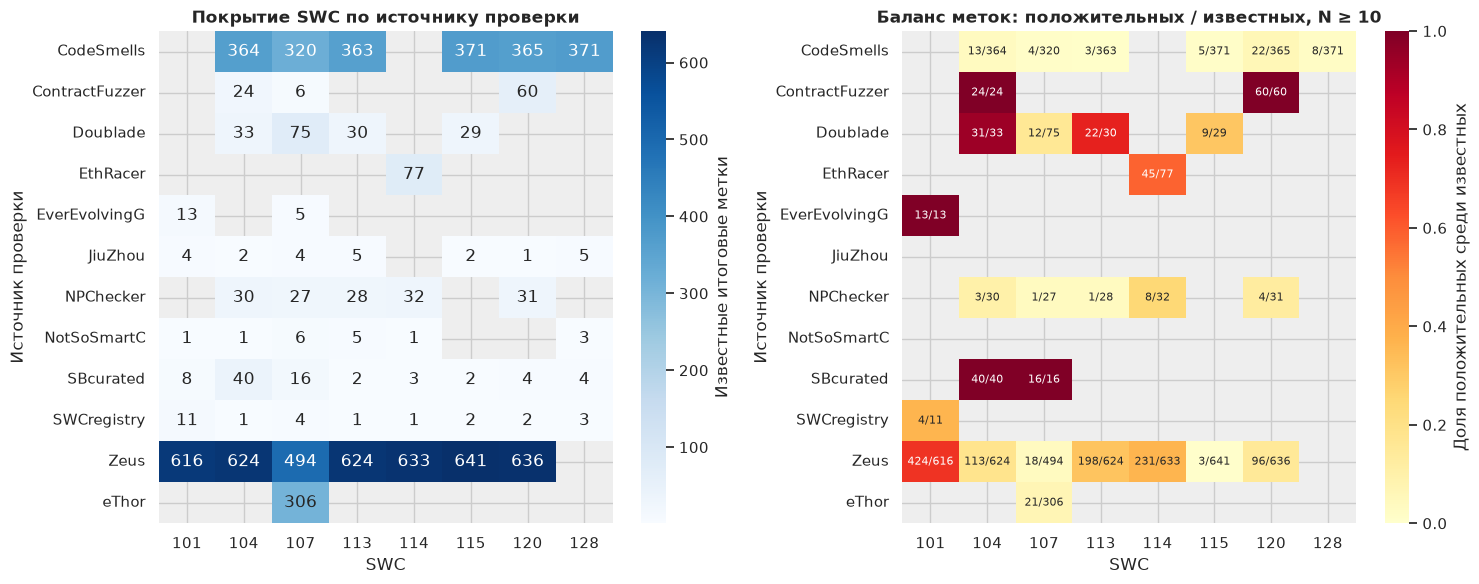

In [44]:
source_known = source_target.pivot(index="dataset", columns="swc", values="known").reindex(columns=CORE_SWCS)
source_rates = source_target.pivot(index="dataset", columns="swc", values="positive_fraction_among_known").reindex(columns=CORE_SWCS)
source_positive = source_target.pivot(index="dataset", columns="swc", values="positive").reindex(columns=CORE_SWCS)
source_annotations = pd.DataFrame("", index=source_known.index, columns=CORE_SWCS)
for dataset in source_known.index:
    for swc in CORE_SWCS:
        n = source_known.at[dataset, swc]
        if pd.notna(n) and n > 0:
            source_annotations.at[dataset, swc] = f"{int(source_positive.at[dataset, swc])}/{int(n)}"

# Порог влияет только на отображение долей, все строки остаются в source_target.
min_source_display = 10
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].set_facecolor("#eeeeee")
axes[1].set_facecolor("#eeeeee")
sns.heatmap(source_known, annot=True, fmt=".0f", cmap="Blues", ax=axes[0],
            cbar_kws={"label": "Известные итоговые метки"})
sns.heatmap(source_rates, mask=source_known.lt(min_source_display) | source_known.isna(),
            annot=source_annotations, fmt="", annot_kws={"fontsize": 8},
            cmap="YlOrRd", vmin=0, vmax=1, ax=axes[1],
            cbar_kws={"label": "Доля положительных среди известных"})
axes[0].set_title("Покрытие SWC по источнику проверки")
axes[1].set_title("Баланс меток: положительных / известных, N ≥ 10")
for ax in axes:
    ax.set(xlabel="SWC", ylabel="Источник проверки")
fig.tight_layout()
plt.show()


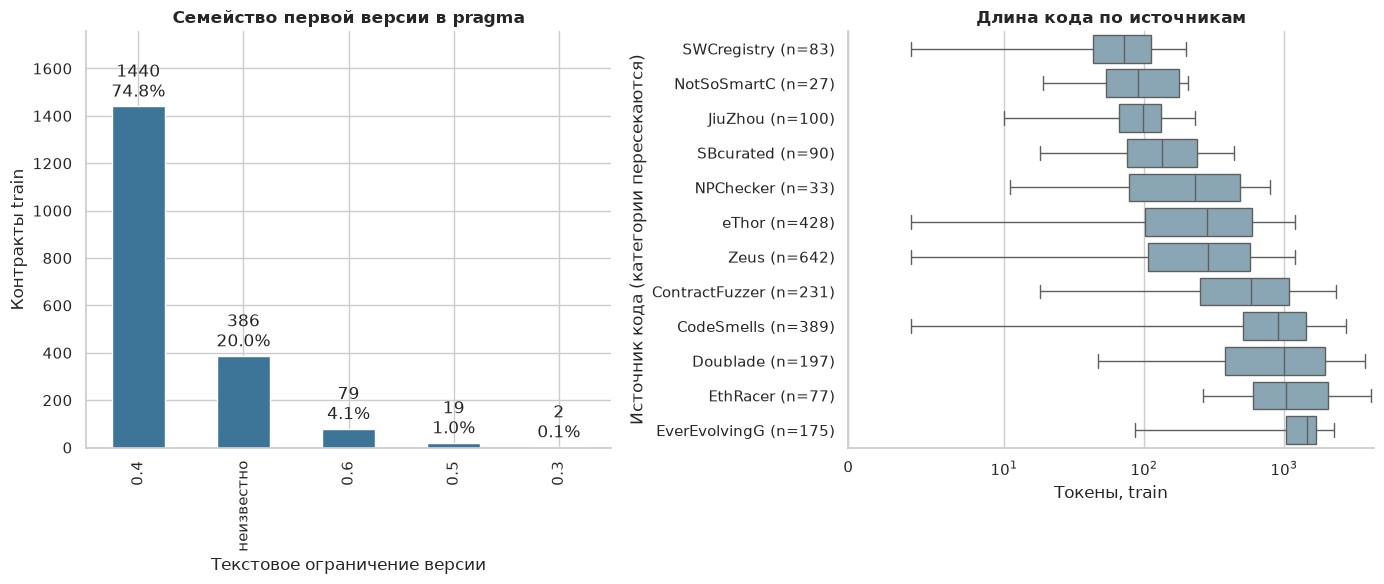

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pragma_counts.plot.bar(y="contracts", legend=False, color="#3d7598", ax=axes[0])
axes[0].bar_label(axes[0].containers[0],
                  labels=[f"{n}\n{n / len(train):.1%}" for n in pragma_counts.contracts], padding=3)
axes[0].set(title="Семейство первой версии в pragma", xlabel="Текстовое ограничение версии",
            ylabel="Контракты train", ylim=(0, pragma_counts.contracts.max() * 1.22))
source_sizes = memberships.groupby("dataset").n_tokens.agg(["size", "median"]).sort_values("median")
sns.boxplot(data=memberships, y="dataset", x="n_tokens", order=source_sizes.index,
            ax=axes[1], color="#83a8bb", showfliers=False)
axes[1].set_yticks(np.arange(len(source_sizes)),
                  labels=[f"{name} (n={int(row['size'])})" for name, row in source_sizes.iterrows()])
axes[1].set_xscale("symlog", linthresh=10)
axes[1].set_xlim(left=0)
axes[1].set(title="Длина кода по источникам", xlabel="Токены, train",
            ylabel="Источник кода (категории пересекаются)")
fig.tight_layout()
plt.show()


In [46]:
context_summary = pd.Series({
    "Неразрешённые внешние родители": int(train.external_bases.ne("").sum()),
    "Имена, отмеченные эвристикой": int(train.has_synthetic_identifiers.sum()),
}, name="Контрактов train")

print('Обзор контекстов контрактов train:')
print(context_summary.to_frame())
print('\n')
print('Примеры контрактов с внешними родителями:')
print(train.loc[train.external_bases.ne(""), ["contract_name", "external_bases", "datasets"]])
print('\n')
print('Примеры контрактов с именами, отмеченными эвристикой:')
print(train.loc[train.has_synthetic_identifiers, ["contract_name", "datasets"]].head(10))


Обзор контекстов контрактов train:
                                Контрактов train
Неразрешённые внешние родители                 2
Имена, отмеченные эвристикой                  31


Примеры контрактов с внешними родителями:
                         contract_name external_bases     datasets
entity_id                                                         
00516ae62751bf410a3d9020      DerivedA           Base  SWCregistry
1e298b37506737329ed6474e      DerivedA           Base  SWCregistry


Примеры контрактов с именами, отмеченными эвристикой:
                                contract_name                   datasets
entity_id                                                               
06e7e53332aae78e24e6a31c             DumbPool                       Zeus
1c469371d6d201d74ce1dc52  SwarmRedistribution                 Zeus|eThor
1d842d62eef02303bc06b95b             SpanCoin    ContractFuzzer|EthRacer
21c11751d47f20f9912cd351          AxiePresale                 CodeSmells
2c30f63921f7

In [47]:
summary = {
    "train_contracts": len(train), "eligible_contracts": len(split),
    "split_sizes": counts.reset_index().to_dict(orient="records"),
    "train_token_median": float(train.n_tokens.median()),
    "train_token_p99": float(train.n_tokens.quantile(.99)),
    "train_token_max": int(train.n_tokens.max()),
    "train_contracts_with_external_bases": int(train.external_bases.ne("").sum()),
    "train_contracts_with_marker_like_identifiers": int(train.has_synthetic_identifiers.sum()),
    "train_pragma_counts": pragma_counts.contracts.to_dict(),
    "strongest_associations": associations.assign(abs_rho=associations.spearman_rho.abs()).nlargest(12, "abs_rho").drop(columns="abs_rho").to_dict(orient="records"),
}
print(json.dumps(summary, indent=2, ensure_ascii=False), flush=True)
pragma_counts


{
  "train_contracts": 1926,
  "eligible_contracts": 2735,
  "split_sizes": [
    {
      "partition": "train",
      "contracts": 1926,
      "groups": 1326,
      "contract_fraction": 0.7042047531992688
    },
    {
      "partition": "validation",
      "contracts": 384,
      "groups": 284,
      "contract_fraction": 0.14040219378427787
    },
    {
      "partition": "test",
      "contracts": 425,
      "groups": 284,
      "contract_fraction": 0.15539305301645337
    }
  ],
  "train_token_median": 497.0,
  "train_token_p99": 8523.5,
  "train_token_max": 12099,
  "train_contracts_with_external_bases": 2,
  "train_contracts_with_marker_like_identifiers": 31,
  "train_pragma_counts": {
    "0.4": 1440,
    "неизвестно": 386,
    "0.6": 79,
    "0.5": 19,
    "0.3": 2
  },
  "strongest_associations": [
    {
      "swc": 107,
      "feature": "n_low_level_calls",
      "n_known_train": 941,
      "positive_n": 75,
      "negative_n": 866,
      "spearman_rho": 0.6157991390215416,
  

,contracts
pragma_family,
0.4,1440
неизвестно,386
0.6,79
0.5,19
0.3,2


### Выводы по совместным меткам и смещению данных

1. **Разметка выбранных классов существенно неполна.** У 475 из 1 926 train-контрактов
   (24,7%) нет ни одной известной метки из восьми выбранных, а все восемь известны
   лишь у 8 объектов. У 620 контрактов все имеющиеся выбранные оценки отрицательные,
   причём полностью известны и отрицательны все восемь только у 2 объектов.
   Поэтому отсутствие наблюдаемой положительной оценки не позволяет присвоить
   общий вердикт безопасности. Сохраняем отдельную маску известных меток каждого SWC.

2. **Несколько слабостей у одного объекта действительно встречаются.** У 342 контрактов
   есть хотя бы две положительные выбранные метки. SWC-101 и SWC-114 одновременно
   положительны у 203 из 611 контрактов с обеими известными оценками (33,2%). Для
   SWC-101 и SWC-128 таких объектов 3 из 16. Малый знаменатель второй пары делает
   её долю крайне неустойчивой. Нулевое пересечение SWC-107 и SWC-115 также требует
   осторожности — среди 815 объектов с обеими известными оценками положительных
   по этим классам всего 34 и 7 соответственно. Эти результаты поддерживают
   многометочную постановку, но не дают основания автоматически дописывать
   неизвестные метки через совместную встречаемость.

3. **Состав меток сильно зависит от источника конкретной проверки.** Например,
   для SWC-104 у CodeSmells положительны 13 из 364 известных итоговых оценок (3,6%),
   а у SmartBugs Curated — 40 из 40. С Zeus связаны 616 из 648 известных train-оценок
   SWC-101. Это свойства отобранных бенчмарков. Модель может использовать особенности
   стиля и состава источников, поэтому перенос следует проверять отдельно.
   При такой проверке общие группы кода должны удерживаться по одну сторону разбиения.
   Источник оценки теперь определяется по исходным проверкам данного SWC; общее
   происхождение кода используется отдельно для сравнения размеров.

4. **Корпус в основном представляет исторический Solidity.** В первой распознанной
   версии ограничения `pragma` семейство 0.4 встречается у 1 440 контрактов (74,8%),
   семейство не определено у 386 (20,0%). Семейство 0.8 в этом распределении отсутствует.
   Текст `pragma` ограничивает допустимые версии и не устанавливает фактически
   использованный компилятор. Для выводов о современных контрактах нужен отдельный
   более свежий корпус и проверка переноса.

5. **Источники различаются и по форме кода.** Медиана длины в SWCregistry составляет
   72 токена, в EverEvolvingG — 1 453. Эти группы содержат соответственно 83 и 175
   контрактов, причём один контракт может иметь несколько источников. Различия
   размера и шаблонов могут влиять на найденные ранее связи признаков с метками.
   У двух train-контрактов отмечены неразрешённые внешние родители — для них стоит
   восстановить контекст. У 31 объекта сработала эвристика имён; её срабатывание
   требует просмотра и само по себе не обосновывает исключение объекта.

**Как используем эти результаты.** Сохраняем неполную разметку, группы и фиксированное
разбиение. Расширение данных стоит направлять на независимые примеры, современные
версии языка и дополнительные проверки редких классов. Следующие представления
кода нужно оценивать также по устойчивости между источниками и при восстановленном
контексте зависимостей. Текущие графики описывают выбранные бенчмарки; доли положительных
меток не являются оценкой распространённости слабостей во всём Ethereum.


## 9. Практическое применение и устойчивость оформления

Данные подходят для исследования способов предварительного поиска подозрительных
участков кода, которые затем проверяет специалист. Для конкретного вывода нужны
исходник, выбранный контракт, его зависимости и понятное происхождение оценки.

Проверим два простых изменения оформления на 12 примерах исследовательской части.
Добавляем комментарий вне кода контракта либо внешние пробелы и переводы строк.
Внутренние выражения и порядок операций сохраняются. Сравниваем токены после
очистки и счётчики конструкций. Дополнительные копии в датасет не записываются.


In [133]:
formatting_rows = []
for entity_id, contract in train.sort_index().head(12).iterrows():
    code = (ROOT / contract.model_input).read_text()
    original_tokens = tokenize(lex(code).clean)
    original_features = code_features(code)
    variants = {
        "Комментарий вне контракта": "// Поясняющий комментарий\n" + code + "\n/* Конец примера */",
        "Внешние пробелы и новые строки": "\n\n " + code + " \n",
    }
    for variant, modified_code in variants.items():
        modified_features = code_features(modified_code)
        formatting_rows.append({
            "entity_id": entity_id, "Изменение": variant,
            "Токены совпадают": tokenize(lex(modified_code).clean) == original_tokens,
            "Основные счётчики совпадают": all(modified_features[f] == original_features[f] for f in FEATURES),
            "Сырая длина текста изменилась": len(modified_code) != len(code),
        })
formatting_checks = pd.DataFrame(formatting_rows)
formatting_checks.groupby("Изменение").agg(
    примеров=("entity_id", "size"),
    токены_совпадают=("Токены совпадают", "all"),
    счётчики_совпадают=("Основные счётчики совпадают", "all"),
    сырая_длина_изменилась=("Сырая длина текста изменилась", "all"),
)


,примеров,токены_совпадают,счётчики_совпадают,сырая_длина_изменилась
Изменение,,,,
Внешние пробелы и новые строки,12,True,True,True
Комментарий вне контракта,12,True,True,True


В этих 24 проверках токены и основные счётчики сохранились. Сырая длина текста
изменилась, поэтому её интерпретация зависит от оформления. Для дальнейшей работы
полезны признаки, устойчивые к таким изменениям. Эти варианты служат проверкой
представления и не увеличивают число независимых программ.

Переименование переменных требует учёта областей видимости. Перестановка операций,
удаление проверок или изменение компилятора могут изменить саму слабость, поэтому
для них потребуется отдельная проверка сохранения смысла. При любых преобразованиях
варианты одной программы должны оставаться в одной группе данных.


## 10. Общий вывод по EDA

Мы изучили CGT — набор проверок программ на Solidity из 13 источников. В исходной
таблице 20 455 строк, каждая описывает отдельную проверку. С ними однозначно связаны
3 088 объявлений — 3 078 контрактов и 10 библиотек. Основной состав исследования
включает 2 735 контрактов, а подробные зависимости изучены на заранее выбранной
исследовательской части из 1 926 объектов.

1. **Главная сложность — неполные оценки.** Одну программу могли проверить только
   на несколько типов проблем. У 475 исследованных контрактов нет известной оценки
   ни по одному из выбранных восьми типов. Все восемь оценок известны лишь у 8
   объектов. Пустые ячейки сохраняем как «неизвестно».

2. **Разные проблемы представлены неравномерно.** В основном наборе некоторые
   типы отмечены всего у 22 или 29 контрактов. Для них особенно важны дополнительные
   разные примеры с проверенными оценками. У 342 объектов исследовательской части
   отмечены минимум две выбранные слабости, поэтому у одной программы может быть
   несколько ответов одновременно.

3. **Похожие программы повторяются.** Один и тот же код встречается в разных
   источниках и вариантах. Мы связали такие реализации в группы. При дальнейшем
   сравнении методов группы целиком сохраняются в одной части данных, чтобы
   проверка показывала работу на другом коде.

4. **Размеры программ сильно различаются.** У половины исследованных объектов
   длина не превышает 497 токенов — отдельных элементов кода. Максимум составляет
   12 099. Длинные программы сохраняем. Для будущих подходов нужно учитывать,
   какая информация теряется при сокращении входа. Формальное правило выбросов
   также отмечает редкие операции, которые важны для нашей задачи.

5. **Отдельные операции дают подсказки, но важен их контекст.** Низкоуровневые
   вызовы найдены у 66 из 75 контрактов с отмеченной reentrancy и у 73 из 866 контрактов
   с отрицательной оценкой. Связь сохраняется среди программ сопоставимой длины.
   Дальше полезно исследовать порядок действий, условия вызовов и проверки доступа.

6. **Выводы зависят от происхождения данных.** Источники различаются по размерам
   программ, набору проверок и доле положительных оценок. У 74,8% исследованных
   контрактов первое распознанное семейство в `pragma` — 0.4. Это преимущественно
   исторический корпус. Расширение стоит направлять на современные проекты,
   независимые примеры и более полную разметку.

Результат этапа — проверенная структура данных и понятные направления дальнейшей
работы. Главные приоритеты проекта — улучшать полноту оценок, сохранять независимость
групп и исследовать операции в контексте программы.